# 로컬 RAG 비교 실습 — 2026 교과과정 책자

> **Ollama(임베딩) + OpenAI API(답변 생성) + Poetry + Jupyter** 로 만드는 RAG 파이프라인.
> 문서 파싱·청킹·임베딩·검색·벡터 DB는 전부 **로컬**에서 돌리고, 마지막 답변 생성 단계만 속도를 위해 OpenAI API를 사용합니다.
> 이번 실습의 핵심은 "RAG를 만든다"가 아니라 **"각 단계의 선택지를 같은 조건에서 돌려 보고 장단점을 숫자로 확인한다"** 입니다.

## 실습 방식

1. 책자에서 뽑은 **공통 평가셋(QA 25문항)** 을 먼저 만든다.
2. 파이프라인 한 단계씩 후보를 바꿔 가며 **같은 평가셋으로 측정**한다. (한 번에 한 변수만 변경)
3. 앞 단계의 우승 후보가 다음 단계의 기본값이 된다.
4. 마지막에 모든 결과를 한 장으로 모아 **우리 조합**을 정한다.

```
PDF ─▶ [파서] ─▶ [청킹] ─▶ [임베딩] ─▶ [벡터 DB] ─▶ [검색 방식] ─▶ [생성 LLM] ─▶ 답변
        2장       3장        4장          5장          6장           7장
```

## 목차

| 장 | 내용 | 비교 대상 |
|---|---|---|
| 1 | 환경 설정과 공통 유틸 | - |
| 2 | 데이터 이해 · PDF 파서 · 평가셋 | pypdf / PyMuPDF / pdfplumber |
| 3 | 청킹 전략 | 고정 길이 / 재귀 / 페이지 / 구조 기반 / 시맨틱 |
| 4 | 임베딩 모델 | bge-m3 / nomic / mxbai / arctic-embed2 / qwen3-embedding |
| 5 | 벡터 DB | NumPy / Chroma / FAISS / Qdrant / LanceDB |
| 6 | 검색 방식 | Dense / BM25 / Hybrid / 메타데이터 필터 / (LLM 리랭킹) |
| 7 | 생성 | 모델 3종, `k` 값 |
| 8 | 종합과 최종 파이프라인 | 요약 대시보드, RAG 전/후 비교 |
| 9 | 과제와 FAQ | - |

> ⏱ 처음 실행하면 임베딩 계산 때문에 시간이 걸립니다. 임베딩은 `.cache/emb/` 에 저장되므로 **두 번째 실행부터는 훨씬 빠릅니다.**

## 1. 환경 설정

### 1.1 사전 준비 (터미널)

```bash
# Ollama 설치: https://ollama.com  →  실행 후 아래 모델 받기
ollama pull bge-m3
ollama pull nomic-embed-text
ollama pull mxbai-embed-large
ollama pull snowflake-arctic-embed2
ollama pull qwen3-embedding:0.6b

# Poetry 환경
poetry install --no-root
poetry run jupyter lab         # 또는 VSCode 에서 .venv 커널 선택
```

### OpenAI API 키 설정 (답변 생성용)

프로젝트 폴더에 `.env` 파일을 만들고 키를 넣습니다. (`.gitignore` 에 이미 제외되어 있어 커밋되지 않습니다.)

```
OPENAI_API_KEY=sk-...
```

> ⚠ 7·8장에서 **질문과 검색된 책자 문단이 OpenAI 서버로 전송**됩니다. 공개 가능한 문서로만 실습하세요. 키는 노트북에 직접 적거나 공유하지 마세요.
> 💰 평가셋 25문항 × 모델 3개 × (k 실험 포함) 수준이라 소형 모델 기준 비용은 크지 않지만, 7장 끝에서 **사용 토큰 수**를 출력하니 대시보드에서 단가와 곱해 확인하세요.

### 1.2 설정과 환경 체크

In [1]:
import json, re, time, hashlib, shutil, inspect, warnings, tempfile, os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import ollama
from concurrent.futures import ThreadPoolExecutor
from dotenv import load_dotenv
from openai import OpenAI
from tqdm.auto import tqdm
from IPython.display import display, Markdown

warnings.filterwarnings("ignore")
load_dotenv()   # .env 의 OPENAI_API_KEY 를 환경변수로 불러옴
from matplotlib import font_manager
_fonts = {f.name for f in font_manager.fontManager.ttflist}
plt.rcParams["font.family"] = next((f for f in ["AppleGothic", "Malgun Gothic", "NanumGothic", "Noto Sans CJK KR"] if f in _fonts), "DejaVu Sans")
plt.rcParams["axes.unicode_minus"] = False

# ── 경로
ROOT = Path.cwd()
DATA = ROOT / "data"
PDF_PATH = DATA / "curriculum_2026.pdf"
QA_PATH = DATA / "qa_eval.json"
CACHE = ROOT / ".cache"
WORK = CACHE / "vdb"
(CACHE / "emb").mkdir(parents=True, exist_ok=True)
shutil.rmtree(WORK, ignore_errors=True); WORK.mkdir(parents=True, exist_ok=True)

# ── 임베딩 모델 후보: 모델마다 query / document 접두어 규칙이 다르다 (공식 권장값)
EMBED_MODELS = {
    "bge-m3":            dict(name="bge-m3",                  doc_prefix="", query_prefix=""),
    "nomic-embed-text":  dict(name="nomic-embed-text",        doc_prefix="search_document: ", query_prefix="search_query: "),
    "mxbai-embed-large": dict(name="mxbai-embed-large",       doc_prefix="", query_prefix="Represent this sentence for searching relevant passages: "),
    "arctic-embed2":     dict(name="snowflake-arctic-embed2", doc_prefix="", query_prefix="query: "),
    "qwen3-embedding":   dict(name="qwen3-embedding:0.6b",    doc_prefix="",
                              query_prefix="Instruct: 대학 교과과정 책자에서 질문과 관련된 문단을 검색하라\nQuery: "),
}
BASE_EMBED = "bge-m3"          # 3장(청킹 비교)에서 고정해서 쓰는 임베딩
# 생성 모델 후보: "openai:<모델명>" 또는 "ollama:<모델명>"
# 사용 가능한 모델명은 계정/시점에 따라 다릅니다 → 아래 환경 체크 셀이 접근 가능 여부를 확인해 줍니다.
GEN_MODELS = ["openai:gpt-4o-mini", "openai:gpt-4.1-mini", "openai:gpt-5.4-mini"]
FAST_MODEL = "openai:gpt-4o-mini"   # 7.3 k 실험 · 리랭킹에 쓰는 저렴한 모델
# 로컬 모델도 섞어 비교하고 싶다면 (느림): GEN_MODELS.append("ollama:llama3.2:latest")
MAX_WORKERS = 8                      # API 호출 병렬도

# ── 환경 체크
def norm_name(n): return n if ":" in n else n + ":latest"
installed = {m.model for m in ollama.list().models}
need = [cfg["name"] for cfg in EMBED_MODELS.values()] + [m.split(":", 1)[1] for m in GEN_MODELS if m.startswith("ollama:")]
missing = [n for n in need if norm_name(n) not in installed]
print("Ollama 연결 OK · 설치된 모델 수:", len(installed))
print("PDF:", PDF_PATH.exists(), "| QA:", QA_PATH.exists())
if missing:
    print("\n⚠ 아래 모델이 없습니다. 터미널에서 받아 주세요:")
    for n in missing: print("   ollama pull", n)
else:
    print("임베딩(로컬) 모델이 모두 준비되었습니다 ✅")

# OpenAI: 키와 모델 접근 가능 여부 확인. 모델 목록에는 있어도 '단종'된 모델이 있으므로 1토큰짜리 실제 호출로 확인한다 (비용 거의 0)
oa = OpenAI() if os.getenv("OPENAI_API_KEY") else None
if oa is None:
    print("\n⚠ OPENAI_API_KEY 가 없습니다. 프로젝트 폴더에 .env 파일을 만들고 OPENAI_API_KEY=sk-... 를 넣은 뒤 커널을 재시작하세요.")
else:
    for m in dict.fromkeys(x for x in GEN_MODELS + [FAST_MODEL] if x.startswith("openai:")):
        try:
            oa.chat.completions.create(model=m.split(":", 1)[1], messages=[{"role": "user", "content": "ok"}], max_completion_tokens=16)
            print("OpenAI 모델 OK:", m)
        except Exception as e:
            print(f"⚠ {m} 사용 불가 → GEN_MODELS/FAST_MODEL 을 바꾸세요 ({str(e)[:80]})")

Ollama 연결 OK · 설치된 모델 수: 15
PDF: True | QA: True
임베딩(로컬) 모델이 모두 준비되었습니다 ✅
OpenAI 모델 OK: openai:gpt-4o-mini
OpenAI 모델 OK: openai:gpt-4.1-mini
OpenAI 모델 OK: openai:gpt-5.4-mini


### 1.3 비교 실험 공통 유틸

- `embed_texts` : Ollama 임베딩 호출 + **디스크 캐시** (같은 입력이면 재계산하지 않고, 최초 계산 시간은 따로 기록)
- 평가 함수 : **Recall@k**, **MRR** — 정답 근거를 포함한 청크가 상위 k개 안에 있는지
- `RESULTS` : 각 장의 결과표를 모아 두었다가 8장에서 한 번에 요약

In [2]:
RESULTS = {}   # 장별 결과표 보관

def norm(s): return re.sub(r"\s+", "", s)
def l2norm(x): return x / np.linalg.norm(x, axis=1, keepdims=True).clip(1e-12)

def embed_texts(key, texts, kind="doc", batch=16, use_cache=True, show=True):
    # 반환: (정규화된 벡터 [N, d], 최초 계산에 걸린 초)
    cfg = EMBED_MODELS[key]
    pre = cfg["doc_prefix"] if kind == "doc" else cfg["query_prefix"]
    texts = [pre + t for t in texts]
    f = None
    if use_cache:
        h = hashlib.sha1((cfg["name"] + kind + "\x00".join(texts)).encode()).hexdigest()
        f = CACHE / "emb" / f"{key.replace(':', '_')}_{kind}_{h[:16]}.npz"
        if f.exists():
            z = np.load(f); return z["vec"], float(z["sec"])
    t0 = time.perf_counter(); out = []
    rng = range(0, len(texts), batch)
    for i in (tqdm(rng, desc=f"embed {key}", leave=False) if show and len(texts) > batch else rng):
        out.append(np.array(ollama.embed(model=cfg["name"], input=texts[i:i + batch]).embeddings, dtype=np.float32))
    vec = l2norm(np.vstack(out)); sec = time.perf_counter() - t0
    if f is not None: np.savez(f, vec=vec, sec=sec)
    return vec, sec

def dir_size_mb(path):
    return sum(p.stat().st_size for p in Path(path).rglob("*") if p.is_file()) / 1e6

def show_table(df, **kw):
    # 열마다 최댓값을 강조해서 보여주기
    cols = kw.get("cols", list(df.select_dtypes("number").columns))
    display(df.style.format(precision=3).highlight_max(subset=[c for c in cols if c in df.columns], color="#cfe8cf"))

## 2. 데이터 이해 · PDF 파서 · 평가셋

### 2.1 2026 교과과정 책자 살펴보기

`data/curriculum_2026.pdf` (약 237쪽). RAG 관점에서 **어려운 점**을 먼저 짚어 봅니다.

| 특징 | RAG에 미치는 영향 |
|---|---|
| 학과별 교과과정이 **표** 형태 (과목명·학수번호·학점·시수) | 파서가 표를 행 단위로 읽지 못하면 "과목명 ↔ 학수번호" 대응이 깨짐 |
| 학과마다 **같은 과목명** (예: 운영체제) 이 다른 학수번호로 반복 | 학과 정보 없이 검색하면 엉뚱한 학과 청크가 올라옴 |
| 졸업요건 문서는 입학년도별로 **거의 같은 문장** 반복 | 의미 검색만으로는 연도 구분이 어려움 |
| 숫자·코드 중심 질문 ("학수번호는?") | 임베딩보다 키워드(BM25)가 유리할 수 있음 |
| 표지 등 텍스트 없는 페이지 | 빈 청크 제거 필요 |

### 2.2 PDF 파서 비교 — pypdf vs PyMuPDF vs pdfplumber

비교 지표
- **속도**: 237쪽 전체 파싱 시간
- **행 보존율**: 정답이 "한 행"에 있는 표 질문에서, 과목명과 학수번호가 **같은 줄**에 파싱되는 비율
- 샘플 출력 눈으로 확인

In [3]:
def parse_pymupdf(path):
    import pymupdf
    with pymupdf.open(path) as d: return [p.get_text() for p in d]

def parse_pypdf(path):
    from pypdf import PdfReader
    return [(p.extract_text() or "") for p in PdfReader(path).pages]

def parse_pdfplumber(path):
    import pdfplumber
    with pdfplumber.open(path) as pdf: return [(p.extract_text() or "") for p in pdf.pages]

PARSERS = {"pymupdf": parse_pymupdf, "pypdf": parse_pypdf, "pdfplumber": parse_pdfplumber}
QA = json.loads(QA_PATH.read_text(encoding="utf-8"))
QA_BY_ID = {q["id"]: q for q in QA}

parsed, rows = {}, []
row_targets = [(q["id"], t) for q in QA for t in q["targets"] if t.get("row")]
for name, fn in PARSERS.items():
    t0 = time.perf_counter(); texts = fn(PDF_PATH); sec = time.perf_counter() - t0
    parsed[name] = texts
    ok = 0
    for _, t in row_targets:
        lines = texts[t["pages"][0] - 1].split("\n")
        ok += any(all(norm(k) in norm(l) for k in t["keywords"]) for l in lines)
    rows.append(dict(parser=name, seconds=sec, total_chars=sum(map(len, texts)),
                     row_fidelity=ok / len(row_targets)))
parser_df = pd.DataFrame(rows).set_index("parser")
RESULTS["parser"] = parser_df
show_table(parser_df, cols=["row_fidelity"])

# 같은 페이지(소프트웨어융합학과 3~4학년, PDF 194쪽)를 파서별로 비교
for name, texts in parsed.items():
    print(f"\n─── {name} " + "─" * 50)
    print("\n".join(texts[193].split("\n")[:12]))

,seconds,total_chars,row_fidelity
parser,,,
pymupdf,1.061,312953,0.000
pypdf,15.680,300888,0.273
pdfplumber,36.155,283515,1.000



─── pymupdf ──────────────────────────────────────────────────
A-7
소프트웨어융합학과
소프트웨어융합학과 학년
3
이수
구분
교     과     목
학수
번호
학 기
1 
학수

─── pypdf ──────────────────────────────────────────────────
A-7
소프트웨어융합학과
소프트웨어융합학과 학년3
이수
구분 교     과     목 학수번호 학 기1 학수번호 학 기2 비       고학점 시수 학점 시수
기본
소양
일반
교양
제 외국어와한문 영역 교양한문2 (5 ) 
(1) 002605 3 3 - -
핵심

─── pdfplumber ──────────────────────────────────────────────────
소프트웨어융합학과
소프트웨어융합학과 3학년
1 학 기 2 학 기
이수 학수 학수
교 과 목 비 고
구분 번호 번호
학점 시수 학점 시수
일반 제2외국어와한문(5영역) 교양한문
002605 3 3 - -
기본 교양 (1)
소양 핵심
공학의이해(7영역) CTO특강 008753 2 2


**관찰 포인트**
- 행 보존율이 낮은 파서는 `운영체제`와 `704512` 가 서로 다른 줄(또는 뒤섞인 순서)에 떨어져서, 이후 어떤 임베딩/검색을 쓰더라도 **"과목 ↔ 학수번호" 정보가 복구되지 않습니다.** (Garbage in, garbage out)
- 속도는 PyMuPDF가 압도적으로 빠르지만, 표가 핵심인 이 문서에서는 **정확도가 우선**이므로 pdfplumber를 사용합니다. (237쪽이라 속도 차이가 큰 문제가 아님)
- 문서가 수만 쪽이라면 선택이 달라질 수 있습니다. → **데이터 규모에 따라 trade-off 가 바뀐다.**

### 2.3 파서 선정과 페이지 메타데이터 추출

학과별 교과과정 페이지는 둘째 줄이 `OO학과 N학년` 형태입니다. 여기서 **학과(dept)** 를 뽑아 메타데이터로 달아 두면 5·6장에서 필터 검색을 실험할 수 있습니다.

In [4]:
BEST_PARSER = parser_df["row_fidelity"].idxmax()
print("선정된 파서:", BEST_PARSER)

GRADE_RE = re.compile(r"^(.+?)\s*([1-4])학년$")
PAGES = []
for i, text in enumerate(parsed[BEST_PARSER], 1):
    dept = ""
    for line in text.split("\n")[:3]:
        m = GRADE_RE.match(line.strip())
        if m: dept = norm(m.group(1)); break
    PAGES.append(dict(page=i, text=text, dept=dept))

n_empty = sum(1 for p in PAGES if not p["text"].strip())
n_dept = sum(1 for p in PAGES if p["dept"])
print(f"총 {len(PAGES)}쪽 · 빈 페이지 {n_empty} · 학과 메타데이터가 붙은 페이지 {n_dept}")
print("예) 194쪽 dept =", PAGES[193]["dept"], "|  99쪽 dept =", PAGES[98]["dept"], "|  58쪽 dept =", repr(PAGES[57]["dept"]))

DEPTS = sorted({p["dept"] for p in PAGES if p["dept"]}, key=len, reverse=True)
def detect_dept(question):
    # 질문에 학과명이 정확히 하나만 등장하면 그 학과를 반환 (메타데이터 필터용)
    qn, found = norm(question), []
    for d in DEPTS:
        if d in qn: found.append(d); qn = qn.replace(d, "")
    return found[0] if len(found) == 1 else None
print("학과 수:", len(DEPTS), "| detect_dept 예:", detect_dept("컴퓨터공학과 3학년 운영체제 학수번호는?"))

선정된 파서: pdfplumber
총 237쪽 · 빈 페이지 8 · 학과 메타데이터가 붙은 페이지 139
예) 194쪽 dept = 소프트웨어융합학과 |  99쪽 dept = 컴퓨터공학과 |  58쪽 dept = ''
학과 수: 81 | detect_dept 예: 컴퓨터공학과


### 2.4 평가용 QA셋

`data/qa_eval.json` — 책자를 직접 읽고 만든 **25문항**입니다. 각 문항에는 정답 근거(페이지 + 반드시 포함돼야 하는 키워드)가 달려 있어서, **검색된 청크가 정답 근거를 담고 있는지를 자동 채점**할 수 있습니다.

| 유형 | 개수 | 설명 |
|---|---|---|
| `table` | 11 | 표에서 한 행을 찾는 질문 (학수번호 등). 학과가 헷갈리기 쉬움 |
| `rule` | 9 | 졸업요건·규정 문장을 찾는 질문. 입학연도별 유사 문장이 distractor |
| `multi` | 1 | 두 군데를 모두 찾아야 하는 종합 질문 |
| `unanswerable` | 3 | 책자에 없는 질문 → "확인할 수 없습니다" 라고 답해야 정답 |

In [5]:
qa_df = pd.DataFrame([dict(id=q["id"], type=q["type"], question=q["question"],
                           gold_pages=sorted({p for t in q["targets"] for p in t["pages"]})) for q in QA])
display(qa_df.groupby("type").size().rename("n").to_frame().T)
display(qa_df.head(8))

QA_ANS = [q for q in QA if q["targets"]]          # 검색 평가 대상 (답이 있는 질문)
QTYPE = {q["id"]: q["type"] for q in QA}

type,multi,rule,table,unanswerable
n,1,9,12,3


,id,type,question,gold_pages
0,q01,table,소프트웨어융합학과 3학년 1학기에 개설되는 운영체제의 학수번호는?,[194]
1,q02,table,컴퓨터공학과 3학년 2학기 운영체제의 학수번호는?,[99]
2,q03,table,소프트웨어융합학과 4학년 졸업논문은 몇 학점인가?,[194]
3,q04,table,소프트웨어융합학과 2학년 1학기 선형대수학의 학수번호는?,[193]
4,q05,table,소프트웨어융합학과 4학년에서 인공지능은 몇 학기에 개설되고 학수번호는 무엇인가?,[194]
5,q06,table,컴퓨터공학과 4학년 졸업논문의 학수번호는?,[99]
6,q07,table,컴퓨터공학과 3학년 1학기에 개설된 컴퓨터구조의 학수번호는?,[99]
7,q08,table,의료헬스케어AI전공 3학년 2학기 기계학습기초의 학수번호는?,[85]


### 2.5 RAG 없이 질문하기 (기준선)

먼저 **책자를 보여주지 않고** 그냥 물어봅니다. 모델이 그럴듯하게 지어내는지(환각) 확인하고, 8장에서 RAG 적용 후와 비교합니다.

In [6]:
USAGE = {}   # 모델별 누적 토큰 사용량 (비용 확인용)

def chat(model, messages, **opts):
    # model: "openai:<이름>" 또는 "ollama:<이름>". 반환: 답변, 소요 시간, 초당 토큰 수
    provider, name = model.split(":", 1)
    t0 = time.perf_counter()
    if provider == "openai":
        kw = dict(model=name, messages=messages, max_completion_tokens=opts.get("num_predict", 400))
        try:
            r = oa.chat.completions.create(temperature=0, **kw)
        except Exception as e:           # 일부 모델은 temperature 를 고정값만 허용 → 옵션 빼고 재시도
            if "temperature" not in str(e): raise
            r = oa.chat.completions.create(**kw)
        sec = time.perf_counter() - t0
        u = USAGE.setdefault(model, dict(prompt=0, completion=0, calls=0))
        u["prompt"] += r.usage.prompt_tokens; u["completion"] += r.usage.completion_tokens; u["calls"] += 1
        return dict(answer=(r.choices[0].message.content or "").strip(), sec=sec, tps=r.usage.completion_tokens / sec)
    # ollama: think=False 로 추론(thinking) 모델의 긴 사고 과정을 끈다. 미지원 모델이면 옵션 없이 재시도
    options = {"temperature": 0, "num_ctx": 8192, **({"num_predict": opts["num_predict"]} if "num_predict" in opts else {})}
    try:
        r = ollama.chat(model=name, messages=messages, options=options, think=False)
    except ollama.ResponseError:
        r = ollama.chat(model=name, messages=messages, options=options)
    sec = time.perf_counter() - t0
    tps = r.eval_count / (r.eval_duration / 1e9) if r.eval_count and r.eval_duration else np.nan
    return dict(answer=r.message.content.strip(), sec=sec, tps=tps)

def pmap(fn, items, desc="", workers=None):
    # API 호출은 대기 시간이 대부분이라 스레드로 병렬 처리하면 크게 빨라진다 (순서 유지)
    items = list(items)
    with ThreadPoolExecutor(workers or MAX_WORKERS) as ex:
        return list(tqdm(ex.map(fn, items), total=len(items), desc=desc, leave=False))

SYS_NO_RAG = "당신은 대학 교과과정 안내 도우미입니다. 한국어로 한두 문장으로 간결히 답하세요. 모르면 '책자에서 확인할 수 없습니다.'라고만 답하세요."

for qid in ["q01", "q10", "q16"]:
    q = QA_BY_ID[qid]
    r = chat(FAST_MODEL, [{"role": "system", "content": SYS_NO_RAG}, {"role": "user", "content": q["question"]}])
    print(f"Q. {q['question']}\nA(RAG 없음). {r['answer']}\n정답 키워드: {q['answer_keywords']}\n")

Q. 소프트웨어융합학과 3학년 1학기에 개설되는 운영체제의 학수번호는?
A(RAG 없음). 책자에서 확인할 수 없습니다.
정답 키워드: ['704512']

Q. 2026학년도 입학생이 공학교육인증과정(공과대학)을 졸업하려면 총 몇 학점 이상을 이수해야 하나?
A(RAG 없음). 책자에서 확인할 수 없습니다.
정답 키워드: ['132']

Q. 입학기준년도가 2013년 이후인 학생은 교직이론을 몇 과목 이상 이수해야 하나?
A(RAG 없음). 책자에서 확인할 수 없습니다.
정답 키워드: ['6과목']



## 3. 청킹 전략 비교

| 후보 | 방식 | 기대 장점 | 기대 단점 |
|---|---|---|---|
| `fixed` | 글자 수로 일정하게 자름 | 구현 최단, 크기 균일 | 표의 행·문장 중간에서 끊김 |
| `recursive` | 문단 → 줄 → 공백 순으로 가능한 큰 단위로 자름 + overlap | 범용 기본값, 문맥 보존 | 표 구조는 모름 |
| `page` | 페이지 1장 = 청크 1개 | 구조·맥락 최대 보존 | 청크가 큼 → 검색이 흐려지고 프롬프트가 길어짐 |
| `structure` | `OO학과 N학년` 블록 단위로 분할 + 헤더 부착 | 이 문서 구조에 최적 | 문서마다 규칙을 직접 짜야 함 |
| `semantic` | 인접 줄 임베딩 유사도가 급락하는 곳에서 분할 | 의미 단위 | 느리고 표 같은 짧은 줄엔 불안정 |

추가로 **헤더 접두어(`[p.194 | 소프트웨어융합학과]`)** 를 임베딩 텍스트 앞에 붙이는 옵션(`+hdr`)도 비교합니다. 청크가 "어느 학과의 것인지" 알려주는 가장 값싼 방법입니다.

> 모든 청커는 **페이지 경계를 넘지 않게** 구현해서 페이지·학과 메타데이터를 유지합니다.

In [7]:
def header(page, dept, extra=""):
    return f"[p.{page}" + (f" | {dept}{extra}" if dept else "") + "]\n"

def make_chunk(page, text, use_header, extra=""):
    h = header(page["page"], page["dept"], extra) if use_header else ""
    return dict(text=text, embed_text=h + text, page=page["page"], dept=page["dept"])

def recursive_split(text, size, overlap, seps=("\n\n", "\n", " ", "")):
    if len(text) <= size: return [text]
    sep = next(s for s in seps if s == "" or s in text)
    parts = text.split(sep) if sep else list(text)
    rest = seps[seps.index(sep) + 1:]
    chunks, cur = [], ""
    for p in parts:
        piece = p if not cur else cur + sep + p
        if len(piece) <= size:
            cur = piece
        else:
            if cur: chunks.append(cur)
            if len(p) > size:
                chunks.extend(recursive_split(p, size, 0, rest)); cur = ""
            else:
                cur = p
    if cur: chunks.append(cur)
    if overlap > 0 and len(chunks) > 1:   # 앞 청크의 끝 일부를 뒤 청크 앞에 붙임
        chunks = [chunks[0]] + [chunks[i - 1][-overlap:] + chunks[i] for i in range(1, len(chunks))]
    return chunks

def chunk_fixed(pages, size=500, overlap=0, use_header=False):
    out = []
    for p in pages:
        t = p["text"].strip()
        for s in range(0, len(t), size - overlap):
            if t[s:s + size].strip(): out.append(make_chunk(p, t[s:s + size], use_header))
    return out

def chunk_recursive(pages, size=500, overlap=75, use_header=False):
    return [make_chunk(p, c, use_header) for p in pages if p["text"].strip()
            for c in recursive_split(p["text"].strip(), size, overlap) if c.strip()]

def chunk_page(pages, use_header=False):
    return [make_chunk(p, p["text"].strip(), use_header) for p in pages if p["text"].strip()]

def chunk_structure(pages, max_chars=1200):
    # 학과 교과과정 페이지: 'OO학과 N학년' 줄마다 새 블록. 그 외 페이지: 재귀 분할(800자)
    out = []
    for p in pages:
        t = p["text"].strip()
        if not t: continue
        if not p["dept"]:
            out += [make_chunk(p, c, True) for c in recursive_split(t, 800, 100) if c.strip()]
            continue
        blocks, cur, grade = [], [], ""
        for line in t.split("\n"):
            m = GRADE_RE.match(line.strip())
            if m and cur and any(GRADE_RE.match(x.strip()) for x in cur):
                blocks.append((grade, "\n".join(cur))); cur = []
            if m: grade = m.group(2) + "학년"
            cur.append(line)
        blocks.append((grade, "\n".join(cur)))
        for g, b in blocks:
            for c in recursive_split(b, max_chars, 0):
                if c.strip(): out.append(make_chunk(p, c, True, extra=f" {g}" if g else ""))
    return out

def chunk_semantic(pages, key=BASE_EMBED, percentile=90, max_chars=900, use_header=True):
    units = [(p, l.strip()) for p in pages for l in p["text"].split("\n") if l.strip()]
    vec, _ = embed_texts(key, [l for _, l in units], batch=64)
    dist = 1 - (vec[1:] * vec[:-1]).sum(1)
    same = np.array([units[i][0] is units[i + 1][0] for i in range(len(units) - 1)])
    thr = np.percentile(dist[same], percentile)
    out, cur, curp = [], [units[0][1]], units[0][0]
    def flush():
        if cur: out.append(make_chunk(curp, "\n".join(cur), use_header))
    for i in range(1, len(units)):
        p, l = units[i]
        if p is not curp or dist[i - 1] > thr or sum(len(x) + 1 for x in cur) + len(l) > max_chars:
            flush(); cur, curp = [], p
        cur.append(l)
    flush()
    return out

def chunk_stats(chunks):
    n = np.array([len(c["text"]) for c in chunks])
    return dict(n_chunks=len(chunks), avg_len=n.mean(), p95_len=np.percentile(n, 95), max_len=n.max())

### 3.1 후보 구현과 통계

먼저 청크가 어떻게 생겼는지 눈으로 확인합니다. 같은 페이지(PDF 194쪽)를 `fixed` 와 `structure` 로 자르면 이렇게 다릅니다.

In [8]:
t0 = time.perf_counter()
CHUNKERS = {
    "fixed_500":         lambda: chunk_fixed(PAGES, 500, 0),
    "recursive_500":     lambda: chunk_recursive(PAGES, 500, 75),
    "recursive_500+hdr": lambda: chunk_recursive(PAGES, 500, 75, use_header=True),
    "page":              lambda: chunk_page(PAGES),
    "page+hdr":          lambda: chunk_page(PAGES, use_header=True),
    "structure":         lambda: chunk_structure(PAGES),
    "semantic":          lambda: chunk_semantic(PAGES),
}
CHUNK_SETS = {}
for name, fn in CHUNKERS.items():
    t = time.perf_counter(); CHUNK_SETS[name] = fn()
    print(f"{name:20s} {len(CHUNK_SETS[name]):5d} 청크  ({time.perf_counter() - t:5.1f}s)")

for name in ["fixed_500", "structure"]:
    c = [c for c in CHUNK_SETS[name] if c["page"] == 194][1]
    print(f"\n━━━ {name} · 194쪽의 청크 예시 ({len(c['text'])}자) ━━━\n{c['embed_text']}")

fixed_500              682 청크  (  0.0s)
recursive_500          698 청크  (  0.0s)
recursive_500+hdr      698 청크  (  0.0s)
page                   229 청크  (  0.0s)
page+hdr               229 청크  (  0.0s)
structure              479 청크  (  0.0s)
semantic              1473 청크  (  0.1s)

━━━ fixed_500 · 194쪽의 청크 예시 (500자) ━━━
sw심화)통신프로그래밍 - - 704836 3 3
엔지니어앙트레프레너십 - - 190426 1 1
개 설 학 점 계 22 23 21 21
일 반 선 택 학 점 계
이 수 학 점 한 계 19 19
※ 기본소양 권장교과목: 제2외국어와한문(교양한문(1)), 의사소통(CTO특강)
※ (sw심화)표기 교과목은 SW/데이터활용역량인증의 ‘전문대체인정교과목’에 해당하며, 이는 인증트랙교과목의 심화모듈 교과목을 대체함.
소프트웨어융합학과 4학년
1 학 기 2 학 기
이수 학수 학수
교 과 목 비 고
구분 번호 번호
학점 시수 학점 시수
기본 핵심
법과생활(6영역) 산업·데이터공학의이해 004189 3 3 - -
소양 교양
전공
(sw심화)종합설계(2) 부학기 3 4 704814 3 4
필수
(sw심화)종합설계(1) 704711 3 3 부학기 3 3
(sw심화)가상현실프로그래밍 704713 3 3 - -
(sw심화)소프트웨어공학 704805 3 3 - -
(sw심화)컴퓨터보안 704811 3 3 

━━━ structure · 194쪽의 청크 예시 (660자) ━━━
[p.194 | 소프트웨어융합학과 4학년]
소프트웨어융합학과 4학년
1 학 기 2 학 기
이수 학수 학수
교 과 목 비 고
구분 번호 번호
학점 시수 학점 시수
기본 핵심
법과생활(6영역) 산업·데이터공학의이해 004189 3 3 - -
소양 교양


### 3.2 청크 길이 분포

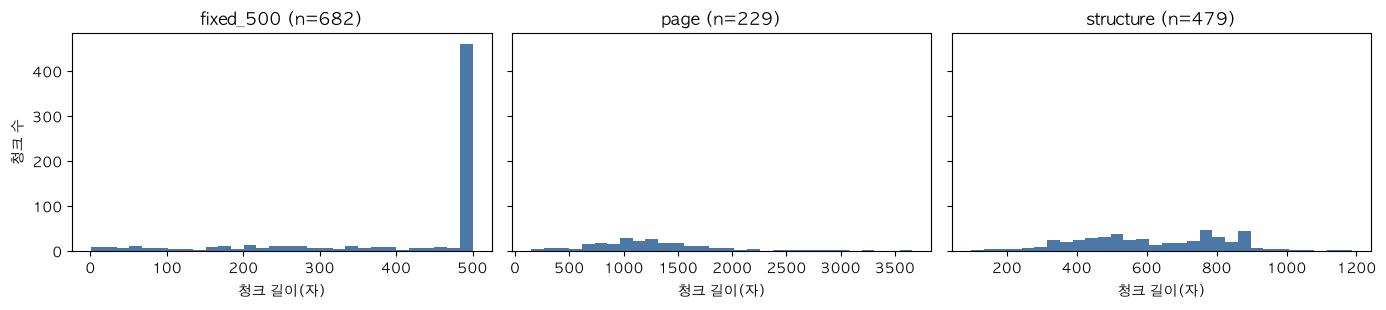

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.2), sharey=True)
for ax, name in zip(axes, ["fixed_500", "page", "structure"]):
    ax.hist([len(c["text"]) for c in CHUNK_SETS[name]], bins=30, color="#4c78a8")
    ax.set_title(f"{name} (n={len(CHUNK_SETS[name])})"); ax.set_xlabel("청크 길이(자)")
axes[0].set_ylabel("청크 수"); plt.tight_layout(); plt.show()

### 3.3 검색 성능 평가 함수

청킹의 좋고 나쁨은 결국 **"정답 근거가 상위 k개 청크 안에 들어오는가"** 로 판단합니다. 같은 임베딩(`bge-m3`)으로 모든 후보를 검색해서 비교합니다.

- **정답 판정**: 청크가 정답 페이지에 속하고, 정답 키워드를 **전부** 포함하면 정답 청크. (키워드가 청크 경계에서 쪼개지면 "정보가 사라진 청크" → 오답)
- **Recall@k**: 상위 k개 안에 든 정답 타깃 비율 (multi 문항은 2개 타깃)
- **MRR**: 첫 정답 청크 순위의 역수 평균 (높을수록 정답이 위쪽에 있음)

In [10]:
def build_relevance(chunks, qa):
    ntexts = [norm(c["text"]) for c in chunks]
    rel = {}
    for q in qa:
        rel[q["id"]] = [{i for i, c in enumerate(chunks)
                         if c["page"] in t["pages"] and all(norm(k) in ntexts[i] for k in t["keywords"])}
                        for t in q["targets"]]
    return rel

def score_rankings(rankings, rel, ks=(1, 3, 5)):
    rows = []
    for qid, targets in rel.items():
        ranked = rankings[qid]; row = {"id": qid}
        for k in ks:
            top = set(ranked[:k]); row[f"R@{k}"] = float(np.mean([bool(top & t) for t in targets]))
        row["MRR"] = next((1 / r for r, i in enumerate(ranked, 1) if any(i in t for t in targets)), 0.0)
        rows.append(row)
    return pd.DataFrame(rows).set_index("id")

def dense_rankings(qa, qvecs, dvecs, topn=20, mask_fn=None):
    out = {}
    for q, qv in zip(qa, qvecs):
        s = dvecs @ qv
        if mask_fn is not None: s = np.where(mask_fn(q), s, -9)
        out[q["id"]] = np.argsort(-s)[:topn].tolist()
    return out

def eval_dense(chunks, embed_key, qa=QA_ANS):
    dvec, sec = embed_texts(embed_key, [c["embed_text"] for c in chunks])
    qvec, _ = embed_texts(embed_key, [q["question"] for q in qa], kind="query")
    df = score_rankings(dense_rankings(qa, qvec, dvec), build_relevance(chunks, qa))
    return df, dvec, qvec, sec

### 3.4 청킹 전략 비교 결과 (임베딩 = bge-m3 고정)

,n_chunks,avg_len,p95_len,max_len,embed_sec,R@1,R@3,R@5,MRR
chunker,,,,,,,,,
fixed_500,682,415.711,500.000,500,36.235,0.455,0.636,0.727,0.567
recursive_500,698,455.904,571.150,575,39.124,0.409,0.636,0.773,0.562
recursive_500+hdr,698,455.904,571.150,575,42.405,0.500,0.727,0.727,0.628
page,229,1238.057,2348.400,3660,36.127,0.455,0.909,1.000,0.695
page+hdr,229,1238.057,2348.400,3660,37.042,0.591,0.932,1.000,0.782
structure,479,616.211,897.100,1188,36.447,0.614,0.909,0.909,0.749
semantic,1473,191.630,861.400,900,49.793,0.273,0.545,0.591,0.432


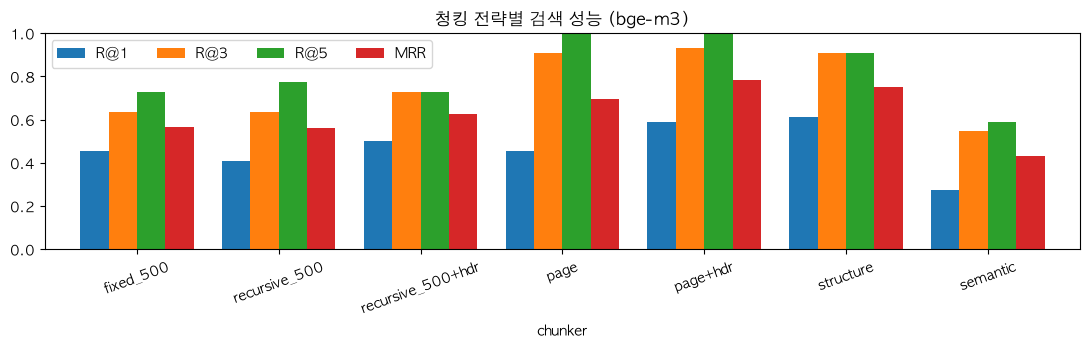

In [11]:
rows, CHUNK_EVAL = [], {}
for name, chunks in CHUNK_SETS.items():
    df, dvec, qvec, sec = eval_dense(chunks, BASE_EMBED)
    CHUNK_EVAL[name] = df
    rows.append(dict(chunker=name, **chunk_stats(chunks), embed_sec=sec, **df[["R@1", "R@3", "R@5", "MRR"]].mean()))
chunk_df = pd.DataFrame(rows).set_index("chunker")
RESULTS["chunk"] = chunk_df
show_table(chunk_df, cols=["R@1", "R@3", "R@5", "MRR"])

ax = chunk_df[["R@1", "R@3", "R@5", "MRR"]].plot.bar(figsize=(11, 3.6), rot=20, width=0.8)
ax.set_title("청킹 전략별 검색 성능 (bge-m3)"); ax.set_ylim(0, 1); ax.legend(ncol=4); plt.tight_layout(); plt.show()

### 3.5 청크 크기 · overlap 변화 실험 (재귀 분할)

같은 `recursive` 에서 **크기**와 **overlap** 만 바꿉니다.

> ⚠ 평가 문항이 22개(답이 있는 질문)뿐이라 **MRR 0.05 안팎의 차이는 우연일 수 있습니다.** 크기에 따라 단조롭게 오르내리지 않는 것도 그 때문입니다. 표를 볼 때는 큰 차이(헤더 유무, page vs semantic 같은)만 의미 있게 읽으세요.

In [12]:
rows = []
for size in [300, 500, 800, 1200]:
    for ov_pct in [0, 15]:
        ch = chunk_recursive(PAGES, size, int(size * ov_pct / 100))
        df, *_ , sec = eval_dense(ch, BASE_EMBED)
        rows.append(dict(size=size, overlap_pct=ov_pct, n_chunks=len(ch), embed_sec=sec, **df[["R@1", "R@5", "MRR"]].mean()))
sweep_df = pd.DataFrame(rows)
RESULTS["chunk_sweep"] = sweep_df
display(sweep_df.pivot(index="size", columns="overlap_pct", values="MRR").style.format(precision=3).set_caption("MRR (행: 청크 크기, 열: overlap %)"))
display(sweep_df.style.format(precision=3))

overlap_pct,0,15
size,,
300,0.412,0.432
500,0.515,0.562
800,0.431,0.534
1200,0.566,0.542


,size,overlap_pct,n_chunks,embed_sec,R@1,R@5,MRR
0,300,0,1099,37.924,0.318,0.545,0.412
1,300,15,1099,41.826,0.318,0.591,0.432
2,500,0,698,35.203,0.364,0.682,0.515
3,500,15,698,39.124,0.409,0.773,0.562
4,800,0,471,34.002,0.273,0.636,0.431
5,800,15,471,37.142,0.318,0.841,0.534
6,1200,0,352,34.908,0.409,0.773,0.566
7,1200,15,352,37.347,0.364,0.727,0.542


### 3.6 결론 — 청킹

- 위 표에서 **MRR이 가장 높은 청킹**을 다음 장의 기본값으로 사용합니다.
- 확인해 볼 것
  1. `recursive_500` 과 `recursive_500+hdr` 의 차이 → **헤더 한 줄**이 "어느 학과인지" 구분하는 데 얼마나 기여하는가
  2. `page` 는 R@5 는 높아도 MRR·R@1 은 어떤가 → 청크가 클수록 "찾기는 하지만 순위가 흐려지는" 경향
  3. `semantic` 은 비용(시간) 대비 이득이 있는가 → 표처럼 줄이 짧은 문서에서는 이득이 작거나 오히려 불리
  4. 크기를 키우면 청크 수는 줄지만 LLM 프롬프트에 들어가는 토큰이 늘어난다 (7장에서 생성 속도에 영향)

In [13]:
BEST_CHUNKER = chunk_df["MRR"].idxmax()
CHUNKS = CHUNK_SETS[BEST_CHUNKER]
print(f"▶ 선정된 청킹: {BEST_CHUNKER}  (청크 {len(CHUNKS)}개, MRR={chunk_df.loc[BEST_CHUNKER, 'MRR']:.3f})")

▶ 선정된 청킹: page+hdr  (청크 229개, MRR=0.782)


## 4. 임베딩 모델 비교

같은 청크(3장 우승), 같은 검색(코사인 유사도)에서 **임베딩 모델만** 바꿉니다.

| 후보 | 특징 (기대) |
|---|---|
| `bge-m3` | 다국어, 한국어 강점. 차원 1024, 컨텍스트 8K |
| `nomic-embed-text` | 경량(274MB). 영어 중심이라 한국어는 약할 것으로 예상 |
| `mxbai-embed-large` | 영어 벤치마크 우수. 한국어는? |
| `arctic-embed2` | 다국어 지원 (Snowflake) |
| `qwen3-embedding:0.6b` | 최신, 다국어·한국어 성능 기대. query 에 **instruction** 을 붙여 사용 |

> 모델마다 **query/document 접두어 규칙**이 다릅니다 (`EMBED_MODELS` 참고). 이걸 무시하면 성능이 눈에 띄게 떨어지기도 합니다.

In [14]:
rows, EMBED_EVAL, EMBED_VECS = [], {}, {}
for key in EMBED_MODELS:
    df, dvec, qvec, sec = eval_dense(CHUNKS, key)
    _, qsec = embed_texts(key, [q["question"] for q in QA_ANS], kind="query")
    EMBED_EVAL[key] = df; EMBED_VECS[key] = (dvec, qvec)
    rows.append(dict(model=key, dim=dvec.shape[1], index_sec=sec, vec_MB=dvec.nbytes / 1e6,
                     **df[["R@1", "R@3", "R@5", "MRR"]].mean()))
embed_df = pd.DataFrame(rows).set_index("model")
RESULTS["embed"] = embed_df
show_table(embed_df, cols=["R@1", "R@3", "R@5", "MRR"])

,dim,index_sec,vec_MB,R@1,R@3,R@5,MRR
model,,,,,,,
bge-m3,1024,37.042,0.938,0.591,0.932,1.000,0.782
nomic-embed-text,768,18.695,0.703,0.341,0.523,0.636,0.486
mxbai-embed-large,1024,31.353,0.938,0.227,0.432,0.477,0.357
arctic-embed2,1024,39.683,0.938,0.341,0.682,0.818,0.572
qwen3-embedding,1024,98.911,0.938,0.614,0.795,0.909,0.758


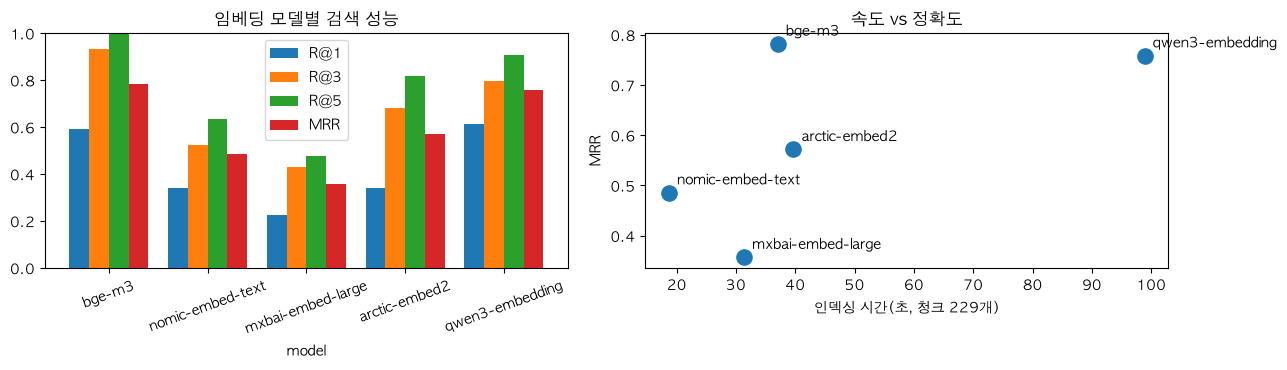

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
embed_df[["R@1", "R@3", "R@5", "MRR"]].plot.bar(ax=axes[0], rot=20, width=0.8)
axes[0].set_title("임베딩 모델별 검색 성능"); axes[0].set_ylim(0, 1)
axes[1].scatter(embed_df["index_sec"], embed_df["MRR"], s=120)
for k, r in embed_df.iterrows(): axes[1].annotate(k, (r["index_sec"], r["MRR"]), textcoords="offset points", xytext=(6, 6))
axes[1].set_xlabel(f"인덱싱 시간(초, 청크 {len(CHUNKS)}개)"); axes[1].set_ylabel("MRR"); axes[1].set_title("속도 vs 정확도")
plt.tight_layout(); plt.show()

### 4.1 질문 유형별 · 질문별 분석

표 질문(학수번호)과 규정 질문에서 모델별 강약이 다른지 봅니다.

In [16]:
by_type = pd.DataFrame({k: df.groupby(df.index.map(QTYPE))["MRR"].mean() for k, df in EMBED_EVAL.items()}).T
display(by_type.style.format(precision=3).highlight_max(color="#cfe8cf").set_caption("유형별 MRR"))

per_q = pd.DataFrame({k: df["R@5"] for k, df in EMBED_EVAL.items()})
per_q.insert(0, "question", [QA_BY_ID[i]["question"][:34] + "…" for i in per_q.index])
display(per_q.style.format(precision=2).background_gradient(cmap="RdYlGn", subset=list(EMBED_MODELS), vmin=0, vmax=1)
        .set_caption("질문별 R@5 (초록=찾음, 빨강=못 찾음)"))

id,multi,rule,table
bge-m3,0.500,0.800,0.792
nomic-embed-text,1.000,0.211,0.649
mxbai-embed-large,0.500,0.386,0.324
arctic-embed2,1.000,0.465,0.616
qwen3-embedding,1.000,0.622,0.840


,question,bge-m3,nomic-embed-text,mxbai-embed-large,arctic-embed2,qwen3-embedding
id,,,,,,
q01,소프트웨어융합학과 3학년 1학기에 개설되는 운영체제의 학수번호…,1.00,1.00,0.00,1.00,1.00
q02,컴퓨터공학과 3학년 2학기 운영체제의 학수번호는?…,1.00,1.00,1.00,1.00,1.00
q03,소프트웨어융합학과 4학년 졸업논문은 몇 학점인가?…,1.00,1.00,0.00,1.00,1.00
q04,소프트웨어융합학과 2학년 1학기 선형대수학의 학수번호는?…,1.00,1.00,0.00,1.00,1.00
q05,소프트웨어융합학과 4학년에서 인공지능은 몇 학기에 개설되고 학…,1.00,1.00,0.00,1.00,1.00
q06,컴퓨터공학과 4학년 졸업논문의 학수번호는?…,1.00,1.00,1.00,1.00,1.00
q07,컴퓨터공학과 3학년 1학기에 개설된 컴퓨터구조의 학수번호는?…,1.00,1.00,1.00,1.00,1.00
q08,의료헬스케어AI전공 3학년 2학기 기계학습기초의 학수번호는?…,1.00,1.00,1.00,1.00,1.00
q09,의료헬스케어AI전공 4학년 시스템설계(캡스톤디자인)의 학수번호…,1.00,1.00,0.00,1.00,1.00


### 4.2 결론 — 임베딩

- 한국어 문서에서 **다국어 모델과 영어 중심 모델의 격차**를 숫자로 확인합니다.
- 정확도가 비슷하다면 **차원·속도·모델 크기**(= 벡터 DB 용량, 인덱싱 시간)가 선택 기준이 됩니다.
- 모든 모델이 공통으로 틀리는 질문이 있다면 → 임베딩이 아니라 **청킹/검색 방식/데이터** 문제일 가능성이 큽니다. (6장에서 BM25 와 메타데이터 필터로 보완)

In [17]:
BEST_EMBED = embed_df["MRR"].idxmax()
DVEC, QVEC_ANS = EMBED_VECS[BEST_EMBED]
print(f"▶ 선정된 임베딩: {BEST_EMBED}  (MRR={embed_df.loc[BEST_EMBED, 'MRR']:.3f}, 차원={DVEC.shape[1]})")

▶ 선정된 임베딩: bge-m3  (MRR=0.782, 차원=1024)


## 5. 벡터 DB 비교

같은 청크, 같은 임베딩 벡터를 **모든 DB에 똑같이 적재**하고 비교합니다.

| 후보 | 형태 | 기대 장점 | 기대 단점 |
|---|---|---|---|
| NumPy (기준선) | 행렬곱 | "DB 없이도 되네?" 를 보여주는 정답 기준 | 필터·영속화 직접 구현, 대규모에서 느림 |
| ChromaDB | 임베디드 + 서버 | 설치·사용 가장 쉬움, 메타데이터 필터, 영속화 | 대규모 성능은 전용 엔진보다 불리 |
| FAISS (Flat / HNSW) | 라이브러리 | 속도·ANN 알고리즘 풍부 | **메타데이터·영속화 기능 없음** (직접 구현) |
| Qdrant (로컬 모드) | 임베디드 + 서버 | 필터링 강력, 운영 확장 쉬움 | API 장황, 로컬 모드는 인덱스 없이 brute-force |
| LanceDB | 파일 기반 임베디드 | 가볍고 디스크 기반, SQL 풍 필터 | 생태계가 상대적으로 작음 |

### 5.1 공통 인터페이스로 래핑

각 DB를 `build / search(query, k, dept=None) / close` 세 메서드로 감쌉니다. **래퍼 코드 길이(LOC)** 도 API 복잡도의 대략적 지표로 비교합니다.

In [18]:
class NumpyDB:
    name = "NumPy"
    def build(self, vecs, metas, path):
        self.v = vecs; self.d = np.array([m["dept"] for m in metas])
    def search(self, q, k, dept=None):
        s = self.v @ q
        if dept: s = np.where(self.d == dept, s, -np.inf)
        return [int(i) for i in np.argsort(-s)[:k] if np.isfinite(s[i])]
    def close(self): pass

class ChromaDB:
    name = "ChromaDB"
    def build(self, vecs, metas, path):
        import chromadb
        self.client = chromadb.PersistentClient(path=str(path))
        self.col = self.client.create_collection("chunks", metadata={"hnsw:space": "cosine"})
        for i in range(0, len(vecs), 500):
            sl = slice(i, i + 500)
            self.col.add(ids=[str(j) for j in range(i, min(i + 500, len(vecs)))],
                         embeddings=vecs[sl].tolist(),
                         metadatas=[{"page": m["page"], "dept": m["dept"]} for m in metas[sl]])
    def search(self, q, k, dept=None):
        r = self.col.query(query_embeddings=[q.tolist()], n_results=k, where={"dept": dept} if dept else None)
        return [int(i) for i in r["ids"][0]]
    def close(self): pass

class FaissFlat:
    name = "FAISS-Flat"
    def build(self, vecs, metas, path):
        import faiss
        self.faiss = faiss; self.idx = self._make(vecs.shape[1]); self.idx.add(vecs)
        self.d = np.array([m["dept"] for m in metas])
    def _make(self, dim): return self.faiss.IndexFlatIP(dim)
    def search(self, q, k, dept=None):
        q = q[None].astype(np.float32)
        if dept:   # FAISS 는 메타데이터를 모른다 → 허용할 id 목록을 직접 만들어 selector 로 전달
            params = self.faiss.SearchParameters()
            params.sel = self.faiss.IDSelectorBatch(np.where(self.d == dept)[0].astype(np.int64))
            _, I = self.idx.search(q, k, params=params)
        else:
            _, I = self.idx.search(q, k)
        return [int(i) for i in I[0] if i >= 0]
    def close(self): pass

class FaissHNSW(FaissFlat):
    name = "FAISS-HNSW"
    def _make(self, dim):
        idx = self.faiss.IndexHNSWFlat(dim, 32, self.faiss.METRIC_INNER_PRODUCT)
        idx.hnsw.efSearch = 64
        return idx

class QdrantDB:
    name = "Qdrant(local)"
    def build(self, vecs, metas, path):
        from qdrant_client import QdrantClient, models
        self.m = models; self.c = QdrantClient(path=str(path))
        self.c.create_collection("chunks", vectors_config=models.VectorParams(size=vecs.shape[1], distance=models.Distance.COSINE))
        for i in range(0, len(vecs), 256):
            self.c.upsert("chunks", points=[models.PointStruct(id=j, vector=vecs[j].tolist(),
                                                           payload={"page": metas[j]["page"], "dept": metas[j]["dept"]})
                                       for j in range(i, min(i + 256, len(vecs)))])
    def search(self, q, k, dept=None):
        f = self.m.Filter(must=[self.m.FieldCondition(key="dept", match=self.m.MatchValue(value=dept))]) if dept else None
        return [p.id for p in self.c.query_points("chunks", query=q.tolist(), limit=k, query_filter=f).points]
    def close(self): self.c.close()

class LanceDBStore:
    name = "LanceDB"
    def build(self, vecs, metas, path):
        import lancedb
        self.t = lancedb.connect(str(path)).create_table(
            "chunks", data=[{"vector": vecs[i], "id": i, "page": metas[i]["page"], "dept": metas[i]["dept"]} for i in range(len(vecs))])
    def search(self, q, k, dept=None):
        s = self.t.search(q.astype(np.float32)).metric("cosine").limit(k)
        if dept: s = s.where(f"dept = '{dept}'", prefilter=True)
        return [int(r["id"]) for r in s.to_list()]
    def close(self): pass

DB_LOC = {'NumpyDB': 9, 'ChromaDB': 15, 'FaissFlat': 17, 'FaissHNSW': 6, 'QdrantDB': 14, 'LanceDBStore': 11}   # 클래스별 코드 줄 수 (아래 값은 노트북 생성 시 자동 계산)
DB_CLASSES = [NumpyDB, ChromaDB, FaissFlat, FaissHNSW, QdrantDB, LanceDBStore]

def new_workdir():
    return Path(tempfile.mkdtemp(dir=WORK))

def bench_db(cls, vecs, metas, qvecs, k=5, reps=3):
    db, path = cls(), new_workdir()
    t0 = time.perf_counter(); db.build(vecs, metas, path); build_s = time.perf_counter() - t0
    lat = []
    for _ in range(reps):
        for q in qvecs:
            t = time.perf_counter(); db.search(q, k); lat.append((time.perf_counter() - t) * 1000)
    return db, dict(db=cls.name, build_s=build_s, p50_ms=np.percentile(lat, 50), p95_ms=np.percentile(lat, 95),
                    disk_MB=dir_size_mb(path), loc=DB_LOC.get(cls.__name__, np.nan))

### 5.2 적재 · 검색 속도 · 정확도 (책자 규모)

- `top5 일치율` : NumPy(정확 검색) 결과와 상위 5개가 얼마나 겹치는가 → ANN 인덱스(HNSW 등)의 근사 오차
- `MRR` : 같은 평가셋으로 검색 정확도를 다시 측정 → **DB를 바꿔도 정확도는 거의 같아야 정상**

In [19]:
metas = [{"page": c["page"], "dept": c["dept"]} for c in CHUNKS]
exact = NumpyDB(); exact.build(DVEC, metas, None)
rel_best = build_relevance(CHUNKS, QA_ANS)

rows, DBS = [], {}
for cls in DB_CLASSES:
    try:
        db, r = bench_db(cls, DVEC, metas, QVEC_ANS)
        DBS[cls.name] = db
        agree = np.mean([len(set(db.search(q, 5)) & set(exact.search(q, 5))) / 5 for q in QVEC_ANS])
        rank = {q["id"]: db.search(qv, 20) for q, qv in zip(QA_ANS, QVEC_ANS)}
        r.update(top5_agree=agree, MRR=score_rankings(rank, rel_best)["MRR"].mean())
        rows.append(r)
    except Exception as e:
        print(f"⚠ {cls.name} 실패: {type(e).__name__}: {e}")
vdb_df = pd.DataFrame(rows).set_index("db")
RESULTS["vdb"] = vdb_df
display(vdb_df.style.format(precision=3)
        .highlight_min(subset=["build_s", "p50_ms", "p95_ms", "disk_MB", "loc"], color="#cfe8cf")
        .highlight_max(subset=["top5_agree", "MRR"], color="#cfe8cf"))

,build_s,p50_ms,p95_ms,disk_MB,loc,top5_agree,MRR
db,,,,,,,
NumPy,0.000,0.014,0.019,0.000,9,1.000,0.782
ChromaDB,0.936,0.569,0.638,1.727,15,1.000,0.782
FAISS-Flat,0.037,0.019,0.022,0.000,17,1.000,0.782
FAISS-HNSW,0.009,0.031,0.037,0.000,6,1.000,0.782
Qdrant(local),0.352,0.342,0.381,2.204,14,1.000,0.782
LanceDB,0.718,1.519,1.784,0.944,11,1.000,0.782


### 5.3 메타데이터 필터 검색

질문에 학과명이 하나만 등장하는 경우(`detect_dept`), 그 학과 청크 안에서만 검색해 봅니다. 
**"운영체제" 같은 과목은 여러 학과에 있으므로** 필터가 정확도를 올리는지, 어떤 DB가 필터를 지원/구현하기 쉬운지 확인합니다.

In [20]:
dept_of = {q["id"]: detect_dept(q["question"]) for q in QA_ANS}
filt_q = [(q, qv) for q, qv in zip(QA_ANS, QVEC_ANS) if dept_of[q["id"]]]
print(f"학과가 감지된 질문: {len(filt_q)} / {len(QA_ANS)}")

rows = []
for name, db in DBS.items():
    if name == "FAISS-HNSW": continue          # HNSW + selector 는 6장 실험 범위 밖
    try:
        base = {q["id"]: db.search(qv, 20) for q, qv in filt_q}
        flt = {q["id"]: db.search(qv, 20, dept=dept_of[q["id"]]) for q, qv in filt_q}
        rel = {q["id"]: rel_best[q["id"]] for q, _ in filt_q}
        only_dept = all(CHUNKS[i]["dept"] == dept_of[q["id"]] for q, _ in filt_q for i in flt[q["id"]])
        rows.append(dict(db=name, MRR_no_filter=score_rankings(base, rel)["MRR"].mean(),
                         MRR_dept_filter=score_rankings(flt, rel)["MRR"].mean(), filter_respected=only_dept))
    except Exception as e:
        rows.append(dict(db=name, MRR_no_filter=np.nan, MRR_dept_filter=np.nan, filter_respected=f"오류: {type(e).__name__}"))
filter_df = pd.DataFrame(rows).set_index("db")
RESULTS["vdb_filter"] = filter_df
display(filter_df.style.format(precision=3))

학과가 감지된 질문: 13 / 22


,MRR_no_filter,MRR_dept_filter,filter_respected
db,,,
NumPy,0.785,0.615,True
ChromaDB,0.785,0.615,True
FAISS-Flat,0.785,0.615,True
Qdrant(local),0.785,0.615,True
LanceDB,0.785,0.615,True


> 💡 **필터가 항상 이득은 아닙니다 — 이 실험에서는 오히려 MRR이 떨어집니다.** 이유는 두 가지입니다.
> 1. **질문 속 학과명 ≠ 찾는 페이지의 학과.** "산업·데이터공학과의 MSC 학점은?", "게임소프트웨어전공의 MSC 학점은?" 은 학과명이 나오지만 정답은 **졸업요건(일반 규정) 페이지**에 있고, 그 페이지에는 `dept` 메타데이터가 없어서 필터가 정답을 통째로 걸러냅니다.
> 2. **메타데이터가 비어 있는 페이지** (예: 홍익챌린지 학수번호 목록 페이지) 도 마찬가지입니다.
>
> 필터는 "메타데이터 품질" + "질문 의도 파악(이 질문이 학과 교과과정 표를 묻는가?)"이 함께 갖춰져야 이득입니다. 표를 묻는 `table` 질문만 따로 보면 어떤지 6장에서 유형별로 확인합니다.

### 5.4 규모가 커지면? (합성 벡터 스케일 테스트)

책자는 청크가 수백~천 개라서 어떤 DB를 써도 차이가 거의 없습니다. 벡터 수를 키우면(합성 랜덤 벡터) 선택이 달라지는지 확인합니다.

> `SCALE_N` 을 올리면 더 극적인 차이를 볼 수 있지만, 시간이 오래 걸립니다.

In [21]:
SCALE_N = 20_000
rng = np.random.default_rng(0)
big = l2norm(rng.standard_normal((SCALE_N, DVEC.shape[1])).astype(np.float32))
big_meta = [{"page": i % 237, "dept": f"dept{i % 20}"} for i in range(SCALE_N)]
big_q = l2norm(rng.standard_normal((50, DVEC.shape[1])).astype(np.float32))
big_exact = NumpyDB(); big_exact.build(big, big_meta, None)

rows = []
for cls in DB_CLASSES:
    try:
        db, r = bench_db(cls, big, big_meta, big_q, reps=2)
        r["top5_agree"] = np.mean([len(set(db.search(q, 5)) & set(big_exact.search(q, 5))) / 5 for q in big_q[:20]])
        rows.append(r); db.close()
    except Exception as e:
        print(f"⚠ {cls.name} 실패: {type(e).__name__}: {e}")
scale_df = pd.DataFrame(rows).set_index("db").drop(columns="loc")
RESULTS["vdb_scale"] = scale_df
print(f"벡터 {SCALE_N:,}개 × {DVEC.shape[1]}차원 (랜덤 벡터라 top5 일치율은 ANN 근사 오차의 '최악 사례')")
display(scale_df.style.format(precision=3).highlight_min(subset=["build_s", "p50_ms", "p95_ms"], color="#cfe8cf")
        .highlight_max(subset=["top5_agree"], color="#cfe8cf"))

벡터 20,000개 × 1024차원 (랜덤 벡터라 top5 일치율은 ANN 근사 오차의 '최악 사례')


,build_s,p50_ms,p95_ms,disk_MB,top5_agree
db,,,,,
NumPy,0.001,2.058,2.231,0.000,1.000
ChromaDB,20.980,3.700,4.257,95.240,0.370
FAISS-Flat,0.007,0.842,0.997,0.000,1.000
FAISS-HNSW,3.051,0.504,0.641,0.000,0.290
Qdrant(local),10.200,12.716,17.479,191.837,1.000
LanceDB,0.362,9.698,11.202,81.992,1.000


### 5.5 결론 — 벡터 DB

| 상황 | 추천 |
|---|---|
| 수천 개 이하, 빠르게 프로토타입 | **NumPy / Chroma** — 충분히 빠르고 코드가 짧다 |
| 메타데이터 필터 + 영속화가 필요 | **Chroma / Qdrant / LanceDB** |
| 순수 속도, 대규모 ANN, 직접 제어 | **FAISS** (메타데이터·저장은 직접) |
| 운영·확장(서버, 샤딩, 필터 최적화) | **Qdrant 서버**, pgvector 등 |

- 책자 규모에서는 **정확도 차이가 거의 없습니다** (5.2의 MRR 열) → DB 선택은 정확도가 아니라 **기능·운영·코드 복잡도**의 문제입니다.
- ANN(HNSW)은 정확 검색 대비 일치율이 100% 미만일 수 있지만, 규모가 클 때 속도 이득이 큽니다.
- Qdrant 로컬 모드처럼 "인덱스 없이 brute-force" 로 동작하는 모드는 규모가 커질수록 느려집니다.

이후 실험은 **ChromaDB 대신 NumPy 검색 + 직접 구현한 BM25** 를 쓰는 편이 하이브리드 구현에 단순하므로, 6장은 NumPy 기반으로 진행합니다. (DB 교체는 `search()` 한 군데만 바꾸면 됩니다.)

## 6. 검색 방식 비교

| 후보 | 방식 | 기대 장점 | 기대 단점 |
|---|---|---|---|
| Dense | 임베딩 코사인 유사도 | 의미가 비슷하면 표현이 달라도 찾음 | **코드·숫자·고유명사에 약함** |
| BM25 (공백 토큰) | 단어 빈도 기반 | 정확한 키워드 일치에 강함 | 한국어 조사("운영체제의") 때문에 매칭 실패 |
| BM25 (Kiwi 형태소) | 형태소 분석 후 BM25 | 조사 분리로 한국어 매칭 개선 | 형태소 분석 비용·사전 의존 |
| Hybrid (RRF) | Dense + BM25 순위 결합 | 서로의 약점 보완 | 구현·튜닝 요소 증가 |
| + 학과 필터 | 질문의 학과명으로 후보 제한 | 동명 과목 혼동 제거 | 메타데이터가 틀리면 정답 소실 |
| + LLM 리랭킹 (선택) | 상위 후보를 LLM이 재채점 | 정밀도 향상 | 느림(후보 수 × LLM 호출) |

In [22]:
from rank_bm25 import BM25Okapi
from kiwipiepy import Kiwi

kiwi = Kiwi()
KEEP_TAGS = {"NNG", "NNP", "NNB", "SL", "SN", "XR", "VV", "VA"}
def tok_ws(t): return t.lower().split()
def tok_kiwi(t): return [x.form.lower() for x in kiwi.tokenize(t) if x.tag in KEEP_TAGS]

print("공백 토큰 :", tok_ws("소프트웨어융합학과 3학년 운영체제의 학수번호는?"))
print("Kiwi 토큰 :", tok_kiwi("소프트웨어융합학과 3학년 운영체제의 학수번호는?"))

t0 = time.perf_counter()
doc_texts = [c["embed_text"] for c in CHUNKS]
BM25 = {"ws": BM25Okapi([tok_ws(t) for t in doc_texts]), "kiwi": BM25Okapi([tok_kiwi(t) for t in doc_texts])}
print(f"BM25 인덱스 구축 {time.perf_counter() - t0:.1f}s")

공백 토큰 : ['소프트웨어융합학과', '3학년', '운영체제의', '학수번호는?']
Kiwi 토큰 : ['소프트웨어', '융합', '학과', '3', '학년', '운영', '체제', '학', '수', '번호']
BM25 인덱스 구축 1.3s


In [23]:
CHUNK_DEPT = np.array([c["dept"] for c in CHUNKS])
QVEC_CACHE = {q["question"]: v for q, v in zip(QA_ANS, QVEC_ANS)}

def qvec_of(question, key=None):
    key = key or BEST_EMBED
    if question not in QVEC_CACHE:
        QVEC_CACHE[question] = embed_texts(key, [question], kind="query", use_cache=False, show=False)[0][0]
    return QVEC_CACHE[question]

def scores_of(question, mode):
    if mode == "dense": return DVEC @ qvec_of(question)
    return BM25[mode].get_scores(tok_ws(question) if mode == "ws" else tok_kiwi(question))

def rank_scores(s, dept=None):
    if dept: s = np.where(CHUNK_DEPT == dept, s, -1e9)
    return np.argsort(-s, kind="stable")

def rrf(rank_lists, k=60, topn=50):
    sc = {}
    for rl in rank_lists:
        for r, i in enumerate(rl[:topn], 1): sc[i] = sc.get(i, 0) + 1 / (k + r)
    return [i for i, _ in sorted(sc.items(), key=lambda x: -x[1])]

def retrieve(question, mode="hybrid", use_filter=False, topn=20):
    dept = detect_dept(question) if use_filter else None
    if mode == "hybrid":
        rls = [rank_scores(scores_of(question, m), dept)[:50].tolist() for m in ("dense", "kiwi")]
        return rrf(rls)[:topn]
    return rank_scores(scores_of(question, mode), dept)[:topn].tolist()

### 6.1 검색 방식별 성능

In [24]:
STRATS = {
    "dense":              dict(mode="dense"),
    "bm25 (공백)":         dict(mode="ws"),
    "bm25 (kiwi)":        dict(mode="kiwi"),
    "hybrid":             dict(mode="hybrid"),
    "dense + 학과필터":     dict(mode="dense",  use_filter=True),
    "hybrid + 학과필터":    dict(mode="hybrid", use_filter=True),
}
rows, STRAT_EVAL = [], {}
for name, kw in STRATS.items():
    t0 = time.perf_counter()
    rank = {q["id"]: retrieve(q["question"], **kw) for q in QA_ANS}
    ms = (time.perf_counter() - t0) / len(QA_ANS) * 1000
    df = score_rankings(rank, rel_best); STRAT_EVAL[name] = df
    rows.append(dict(strategy=name, ms_per_query=ms, **df[["R@1", "R@3", "R@5", "MRR"]].mean()))
retr_df = pd.DataFrame(rows).set_index("strategy")
RESULTS["retrieval"] = retr_df
show_table(retr_df, cols=["R@1", "R@3", "R@5", "MRR"])

by_type = pd.DataFrame({k: df.groupby(df.index.map(QTYPE))["MRR"].mean() for k, df in STRAT_EVAL.items()}).T
display(by_type.style.format(precision=3).highlight_max(color="#cfe8cf").set_caption("유형별 MRR"))

,ms_per_query,R@1,R@3,R@5,MRR
strategy,,,,,
dense,0.049,0.591,0.932,1.000,0.782
bm25 (공백),0.346,0.341,0.523,0.614,0.504
bm25 (kiwi),1.036,0.432,0.614,0.750,0.606
hybrid,0.520,0.682,0.955,1.000,0.812
dense + 학과필터,0.019,0.545,0.795,0.818,0.701
hybrid + 학과필터,0.640,0.545,0.818,0.818,0.694


id,multi,rule,table
dense,0.500,0.800,0.792
bm25 (공백),1.000,0.351,0.576
bm25 (kiwi),1.000,0.485,0.664
hybrid,0.500,0.781,0.861
dense + 학과필터,0.500,0.603,0.792
hybrid + 학과필터,0.500,0.584,0.792


### 6.2 (선택) LLM 리랭킹

상위 10개 후보를 LLM(`FAST_MODEL`, OpenAI)에게 "질문과 관련 있는가?" 를 0~10점으로 채점시켜 재정렬합니다. 후보 × 질문 수만큼(약 250회) API 호출이 필요해서 **비용과 시간이 추가로 듭니다.** 기본값은 꺼져 있습니다. (`RUN_RERANK = True` 로 켜기)

In [25]:
RUN_RERANK = False
RERANK_N = 10

def llm_rerank(question, cand, model=FAST_MODEL):
    scored = []
    for i in cand[:RERANK_N]:
        prompt = (f"질문: {question}\n\n문단:\n{CHUNKS[i]['embed_text'][:1200]}\n\n"
                  "이 문단이 질문의 정답 근거를 담고 있습니까? 학과·학년·학기가 질문과 일치해야 합니다. 0~10 사이 숫자 하나만 출력하세요.")
        out = chat(model, [{"role": "user", "content": prompt}], num_predict=4)["answer"]
        m = re.search(r"\d+", out); scored.append((int(m.group()) if m else 0, -len(scored), i))
    return [i for _, _, i in sorted(scored, reverse=True)] + cand[RERANK_N:]

if RUN_RERANK:
    t0 = time.perf_counter()
    cands = {q["id"]: retrieve(q["question"], "hybrid", True, 20) for q in QA_ANS}
    out = pmap(lambda q: llm_rerank(q["question"], cands[q["id"]]), QA_ANS, desc="rerank")
    rank = {q["id"]: r for q, r in zip(QA_ANS, out)}
    df = score_rankings(rank, rel_best); STRAT_EVAL["hybrid+필터+LLM리랭크"] = df
    ms = (time.perf_counter() - t0) / len(QA_ANS) * 1000
    retr_df.loc["hybrid+필터+LLM리랭크"] = dict(ms_per_query=ms, **df[["R@1", "R@3", "R@5", "MRR"]].mean())
    RESULTS["retrieval"] = retr_df; show_table(retr_df, cols=["R@1", "R@3", "R@5", "MRR"])
else:
    print("리랭킹 건너뜀 (RUN_RERANK=False)")

리랭킹 건너뜀 (RUN_RERANK=False)


### 6.3 결론 — 검색 방식

- 학수번호·코드 질문(`table`)에서 **Dense 와 BM25 중 누가 강한지**, 규정 문장(`rule`)에서는 어떤지 유형별 표로 확인합니다.
- BM25 는 **토크나이저에 따라 성능이 크게 달라집니다.** 한국어는 형태소 분석이 사실상 필수입니다.
- Hybrid 는 한쪽이 틀릴 때 다른 쪽이 보완하므로 **분산(실패 케이스)을 줄이는** 효과가 있습니다.
- 학과 필터는 동명 과목 혼동은 줄여도, **질문에 학과명이 나온다고 해서 그 학과 페이지를 찾는 건 아닙니다.** 졸업요건 같은 일반 규정 질문에서는 정답 페이지를 걸러내 `rule` 유형 점수가 크게 떨어집니다. 필터를 쓰려면 질문 의도 분류가 먼저 필요합니다. (과제 3 참고)

In [26]:
retr_main = retr_df[retr_df["R@5"] >= 0]
BEST_STRATEGY = retr_main["MRR"].idxmax()
STRAT_KW = {**STRATS, "hybrid+필터+LLM리랭크": dict(mode="hybrid", use_filter=True)}[BEST_STRATEGY]
print(f"▶ 선정된 검색 방식: {BEST_STRATEGY}  (MRR={retr_main.loc[BEST_STRATEGY, 'MRR']:.3f})")

▶ 선정된 검색 방식: hybrid  (MRR=0.812)


## 7. 생성 단계

검색이 끝났으니 **검색된 청크를 프롬프트에 넣어** 답을 만듭니다.

### 7.1 프롬프트 설계

핵심 규칙 3가지
1. **참고자료에 있는 내용만** 근거로 답한다 (환각 억제)
2. **학과·학년·학기가 일치하는 자료만** 쓴다 (이 문서의 대표 함정)
3. 근거가 없으면 정해진 문장으로 **거절**한다 → 거절 문장이 고정되어 있어야 자동 채점 가능

채점 기준
- 답이 있는 질문: 정답 키워드가 **모두** 답변에 포함되면 정답 (`A|B` 로 쓰면 표기 차이를 허용)
- `unanswerable` 질문: "책자에서 확인할 수 없습니다" 로 거절하면 정답

In [27]:
SYS_RAG = ("당신은 대학 교과과정 책자를 안내하는 도우미입니다. 반드시 [참고자료]에 있는 내용만 근거로 한국어로 간결하게 답하세요. "
           "질문의 학과·학년·학기와 정확히 일치하는 자료만 사용하세요. "
           "참고자료에서 답을 찾을 수 없으면 다른 말 없이 정확히 '책자에서 확인할 수 없습니다.' 라고만 답하세요.")

def build_context(idx):
    return "\n\n".join(f"[자료 {n} | p.{CHUNKS[i]['page']}" + (f" | {CHUNKS[i]['dept']}" if CHUNKS[i]["dept"] else "") + f"]\n{CHUNKS[i]['text']}"
                        for n, i in enumerate(idx, 1))

def rag_answer(model, question, k=5, strategy_kw=None):
    idx = retrieve(question, **(strategy_kw or STRAT_KW))[:k]
    ctx = build_context(idx)
    r = chat(model, [{"role": "system", "content": SYS_RAG},
                     {"role": "user", "content": f"[참고자료]\n{ctx}\n\n[질문]\n{question}"}])
    return dict(**r, ctx_chars=len(ctx), sources=[CHUNKS[i]["page"] for i in idx])

def judge(q, answer):
    a = norm(answer)
    if q["type"] == "unanswerable": return "확인할수없" in a
    # 키워드에 "A|B" 로 적으면 둘 중 하나만 있어도 인정 (표기 차이 허용: "1/1" 또는 "1학점")
    return "확인할수없" not in a and all(any(norm(alt) in a for alt in k.split("|")) for k in q["answer_keywords"])

demo = rag_answer(FAST_MODEL, QA_BY_ID["q01"]["question"])
print("Q.", QA_BY_ID["q01"]["question"]); print("A.", demo["answer"]); print("근거 페이지:", demo["sources"], "| 컨텍스트", demo["ctx_chars"], "자")

Q. 소프트웨어융합학과 3학년 1학기에 개설되는 운영체제의 학수번호는?
A. 운영체제의 학수번호는 704512입니다.
근거 페이지: [194, 193, 31, 99, 56] | 컨텍스트 7239 자


### 7.2 생성 모델 비교

| 후보 | 기대 |
|---|---|
| `gpt-4o-mini` | 이전 세대 저비용 모델 (기준선) |
| `gpt-4.1-mini` | 지시 따르기·긴 컨텍스트 개선된 소형 모델 |
| `gpt-5.4-mini` | 최신 세대 소형 모델. 정확도 기대, 비용·지연은 더 클 수 있음 |

> 모델명은 `GEN_MODELS` 에서 바꿀 수 있습니다. 로컬 모델(`"ollama:..."`)을 섞으면 **클라우드 vs 로컬** 비교도 됩니다. (단, 로컬은 훨씬 느립니다.)

지표: 정확도(키워드 채점), 거절 정확도, 평균 응답 시간, 초당 토큰 수. **검색 결과(k=5)는 모델과 무관하게 동일**하므로 순수하게 생성 모델 차이만 비교됩니다.

In [28]:
K = 5
RETR = {q["id"]: retrieve(q["question"], **STRAT_KW)[:K] for q in QA}   # 검색은 한 번만 (모델과 무관)
gen_rows, gen_raw = [], []
def run_one(args):
    model, q = args
    ctx = build_context(RETR[q["id"]])
    r = chat(model, [{"role": "system", "content": SYS_RAG}, {"role": "user", "content": f"[참고자료]\n{ctx}\n\n[질문]\n{q['question']}"}])
    return dict(model=model, id=q["id"], type=q["type"], ok=judge(q, r["answer"]), sec=r["sec"], tps=r["tps"],
                answer=r["answer"].replace("\n", " ")[:160])
gen_raw = pmap(run_one, [(m, q) for m in GEN_MODELS for q in QA], desc="생성 평가")
gen_raw = pd.DataFrame(gen_raw)
for model, g in gen_raw.groupby("model"):
    gen_rows.append(dict(model=model, acc_answerable=g[g.type != "unanswerable"].ok.mean(),
                         refusal_acc=g[g.type == "unanswerable"].ok.mean(), acc_all=g.ok.mean(),
                         avg_sec=g.sec.mean(), tokens_per_sec=g.tps.mean()))
gen_df = pd.DataFrame(gen_rows).set_index("model").loc[GEN_MODELS]
RESULTS["gen"] = gen_df
display(gen_df.style.format(precision=3).highlight_max(subset=["acc_answerable", "refusal_acc", "acc_all", "tokens_per_sec"], color="#cfe8cf")
        .highlight_min(subset=["avg_sec"], color="#cfe8cf"))

ok_matrix = gen_raw.pivot(index="id", columns="model", values="ok")[GEN_MODELS].astype(int)
ok_matrix.insert(0, "type", ok_matrix.index.map(QTYPE))
display(ok_matrix.style.background_gradient(cmap="RdYlGn", subset=GEN_MODELS, vmin=0, vmax=1).set_caption("질문별 정답 여부 (1=정답)"))

# 오답이 정말 틀린 건지, 지나치게 거절한 건지 직접 확인 (키워드 채점의 한계도 여기서 보인다)
bad = gen_raw[~gen_raw.ok][["model", "id", "type", "answer"]].copy()
bad["question"] = bad["id"].map(lambda i: QA_BY_ID[i]["question"][:30])
pd.set_option("display.max_colwidth", 90)
display(bad.sort_values(["model", "id"]).reset_index(drop=True))

생성 평가:   0%|          | 0/75 [00:00<?, ?it/s]

,acc_answerable,refusal_acc,acc_all,avg_sec,tokens_per_sec
model,,,,,
openai:gpt-4o-mini,0.864,1.000,0.880,1.118,21.899
openai:gpt-4.1-mini,0.955,1.000,0.960,0.886,36.400
openai:gpt-5.4-mini,0.773,1.000,0.800,0.916,14.119


model,type,openai:gpt-4o-mini,openai:gpt-4.1-mini,openai:gpt-5.4-mini
id,,,,
q01,table,1,1,1
q02,table,0,1,1
q03,table,1,1,1
q04,table,1,1,1
q05,table,1,1,1
q06,table,1,1,1
q07,table,1,1,1
q08,table,0,1,0
q09,table,1,1,1


,model,id,type,answer,question
0,openai:gpt-4.1-mini,q12,rule,"산업·데이터공학과의 MSC 분야별 최소이수학점은 수학 17학점, 전산 6학점입니다. (자료 4, p.10)",산업·데이터공학과의 MSC 분야별 최소이수학점은 얼마인
1,openai:gpt-4o-mini,q02,table,책자에서 확인할 수 없습니다.,컴퓨터공학과 3학년 2학기 운영체제의 학수번호는?
2,openai:gpt-4o-mini,q08,table,책자에서 확인할 수 없습니다.,의료헬스케어AI전공 3학년 2학기 기계학습기초의 학수번
3,openai:gpt-4o-mini,q12,rule,책자에서 확인할 수 없습니다.,산업·데이터공학과의 MSC 분야별 최소이수학점은 얼마인
4,openai:gpt-5.4-mini,q08,table,책자에서 확인할 수 없습니다.,의료헬스케어AI전공 3학년 2학기 기계학습기초의 학수번
5,openai:gpt-5.4-mini,q12,rule,책자에서 확인할 수 없습니다.,산업·데이터공학과의 MSC 분야별 최소이수학점은 얼마인
6,openai:gpt-5.4-mini,q15,rule,책자에서 확인할 수 없습니다.,필수과목이 폐지되었는데 경과조치가 별도로 없다면 그 과
7,openai:gpt-5.4-mini,q17,rule,책자에서 확인할 수 없습니다.,교직실무 과목은 학점과 시수가 어떻게 변경되었나?
8,openai:gpt-5.4-mini,q21,rule,책자에서 확인할 수 없습니다.,비인증과정 대상 게임소프트웨어전공의 MSC 이수 학점은


### 7.3 검색 개수 `k` 에 따른 변화

`k` 를 키우면 정답 근거가 들어올 확률(검색 재현율)은 오르지만, **컨텍스트가 길어져** 느려지고 모델이 헷갈릴 수 있습니다. 가벼운 모델(`FAST_MODEL`)로 확인합니다. API 호출은 병렬(`pmap`)로 처리합니다.

In [29]:
rows = []
for k in [1, 3, 5, 8]:
    def run_k(q):
        r = rag_answer(FAST_MODEL, q["question"], k=k)
        hit = None
        if q["targets"]:
            top = set(retrieve(q["question"], **STRAT_KW)[:k])
            hit = np.mean([bool(top & t) for t in rel_best[q["id"]]])
        return judge(q, r["answer"]), r["sec"], r["ctx_chars"], hit
    res = pmap(run_k, QA, desc=f"k={k}")
    rows.append(dict(k=k, retrieval_recall=np.mean([h for *_, h in res if h is not None]), answer_acc=np.mean([r[0] for r in res]),
                     avg_ctx_chars=np.mean([r[2] for r in res]), avg_sec=np.mean([r[1] for r in res])))
k_df = pd.DataFrame(rows).set_index("k")
RESULTS["k_sweep"] = k_df
display(k_df.style.format(precision=3).highlight_max(subset=["retrieval_recall", "answer_acc"], color="#cfe8cf"))

# 지금까지 사용한 토큰 (모델별 단가 × 토큰 = 비용)
usage_df = pd.DataFrame(USAGE).T
if len(usage_df): display(usage_df.style.set_caption("OpenAI 누적 사용량 (prompt/completion 토큰, 호출 수)"))

k=1:   0%|          | 0/25 [00:00<?, ?it/s]

k=3:   0%|          | 0/25 [00:00<?, ?it/s]

k=5:   0%|          | 0/25 [00:00<?, ?it/s]

k=8:   0%|          | 0/25 [00:00<?, ?it/s]

,retrieval_recall,answer_acc,avg_ctx_chars,avg_sec
k,,,,
1,0.682,0.760,1499.560,0.971
3,0.955,0.880,4691.360,0.991
5,1.000,0.880,7825.760,0.923
8,1.000,0.920,12325.560,1.041


,prompt,completion,calls
openai:gpt-4o-mini,636003,3116,129
openai:gpt-4.1-mini,143979,793,25
openai:gpt-5.4-mini,143954,317,25


### 7.4 실패 분석 — 검색 문제인가, 생성 문제인가?

오답을 **검색 실패**(정답 근거가 top-k 에 없음)와 **생성 실패**(근거는 있는데 모델이 틀림)로 나눠 봅니다. 개선 방향이 완전히 다르기 때문입니다.

In [30]:
BEST_GEN = gen_df.sort_values(["acc_all", "avg_sec"], ascending=[False, True]).index[0]
print("▶ 선정된 생성 모델:", BEST_GEN)

rows = []
for _, r in gen_raw[(gen_raw.model == BEST_GEN) & (~gen_raw.ok)].iterrows():
    q = QA_BY_ID[r["id"]]
    hit = None
    if q["targets"]:
        top = set(retrieve(q["question"], **STRAT_KW)[:K])
        hit = all(bool(top & t) for t in rel_best[q["id"]])
    cause = "해당 없음(거절 실패)" if hit is None else ("생성 실패 (근거는 검색됨)" if hit else "검색 실패 (근거 누락)")
    rows.append(dict(id=r["id"], type=q["type"], cause=cause, question=q["question"][:40], expected=q["answer_keywords"], got=r["answer"][:70]))
fail_df = pd.DataFrame(rows)
print(f"{BEST_GEN} 오답 {len(fail_df)}건")
display(fail_df) if len(fail_df) else print("오답 없음 🎉")

▶ 선정된 생성 모델: openai:gpt-4.1-mini
openai:gpt-4.1-mini 오답 1건


,id,type,cause,question,expected,got
0,q12,rule,생성 실패 (근거는 검색됨),산업·데이터공학과의 MSC 분야별 최소이수학점은 얼마인가?,"[4학점, 3학점, 6학점]","산업·데이터공학과의 MSC 분야별 최소이수학점은 수학 17학점, 전산 6학점입니다. (자료 4, p.10)"


### 7.5 결론 — 생성

- **크기가 큰 모델 ≠ 항상 정확**: 이 과제는 "근거 찾아 옮겨 적기 + 거절" 이라서 지시 따르기와 한국어 처리 능력이 더 중요합니다.
- 오답의 원인이 검색이면 4~6장으로, 생성이면 프롬프트·모델·`k` 로 돌아가 고칩니다.
- `k` 는 "많을수록 좋다" 가 아닙니다. 정확도 · 속도의 균형점을 표에서 찾으세요.

## 8. 종합과 최종 파이프라인

### 8.1 요약 대시보드

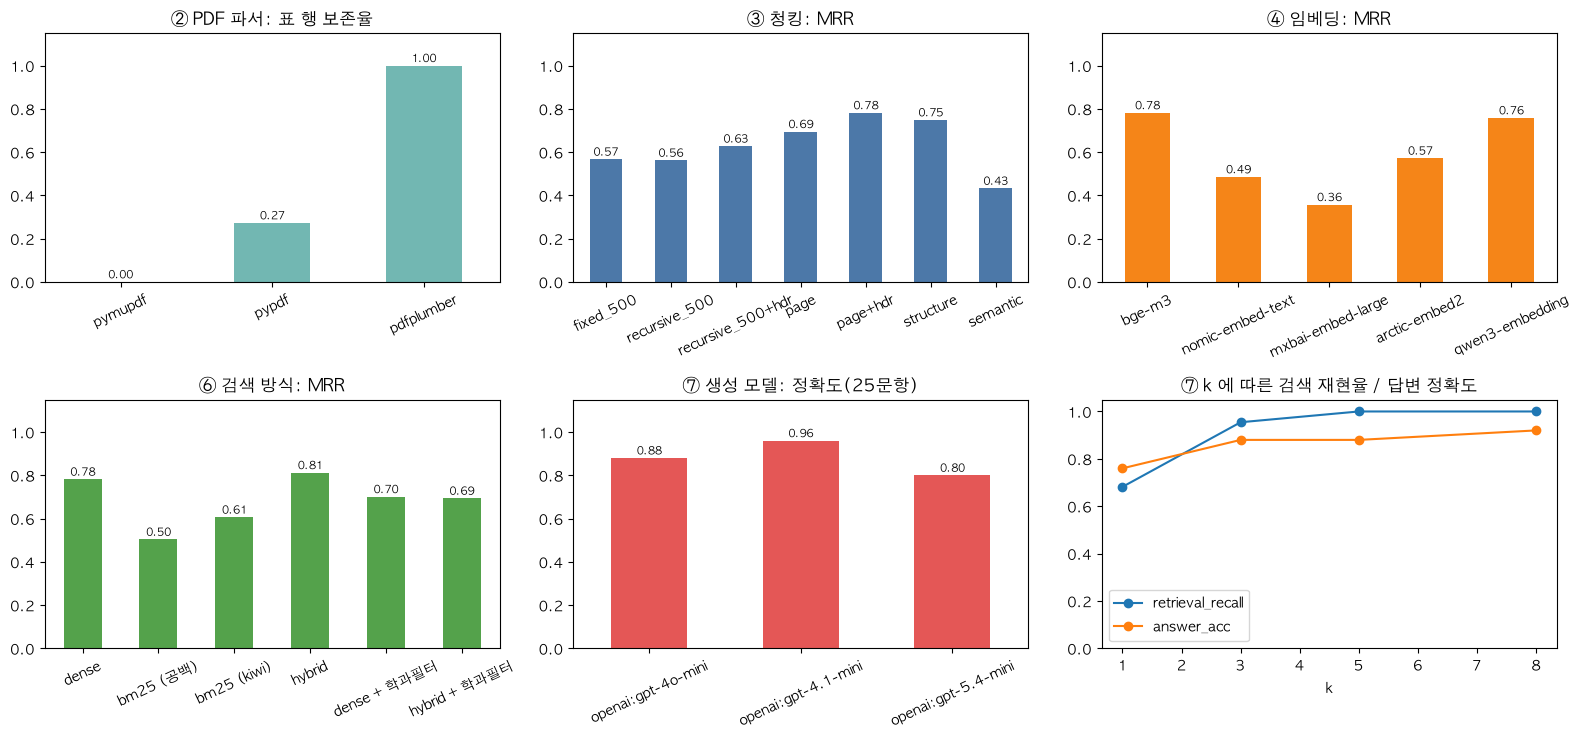

In [31]:
fig, axes = plt.subplots(2, 3, figsize=(16, 7.5))
def bar(ax, s, title, color="#4c78a8", ylabel=""):
    s.plot.bar(ax=ax, color=color, rot=25); ax.set_title(title); ax.set_ylabel(ylabel); ax.set_xlabel("")
    for p in ax.patches: ax.annotate(f"{p.get_height():.2f}", (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom", fontsize=8)
bar(axes[0, 0], RESULTS["parser"]["row_fidelity"], "② PDF 파서: 표 행 보존율", "#72b7b2")
bar(axes[0, 1], RESULTS["chunk"]["MRR"], "③ 청킹: MRR", "#4c78a8")
bar(axes[0, 2], RESULTS["embed"]["MRR"], "④ 임베딩: MRR", "#f58518")
bar(axes[1, 0], RESULTS["retrieval"]["MRR"], "⑥ 검색 방식: MRR", "#54a24b")
bar(axes[1, 1], RESULTS["gen"]["acc_all"], "⑦ 생성 모델: 정확도(25문항)", "#e45756")
RESULTS["k_sweep"][["retrieval_recall", "answer_acc"]].plot(ax=axes[1, 2], marker="o"); axes[1, 2].set_title("⑦ k 에 따른 검색 재현율 / 답변 정확도"); axes[1, 2].set_ylim(0, 1.05)
for ax in axes.flat[:5]: ax.set_ylim(0, 1.15)
plt.tight_layout(); plt.show()

### 8.2 우리 조합 선정

각 장의 우승 후보와 **선택 근거**를 표로 정리합니다. 정확도뿐 아니라 속도·리소스·구현 난이도까지 함께 보세요.

In [32]:
summary = pd.DataFrame([
    ("PDF 파서",   BEST_PARSER,   f"행 보존율 {RESULTS['parser'].loc[BEST_PARSER, 'row_fidelity']:.2f}",
                                  "표 중심 문서는 파서가 상한선을 결정"),
    ("청킹",       BEST_CHUNKER,  f"MRR {chunk_df.loc[BEST_CHUNKER, 'MRR']:.3f}",
                                  "헤더/구조 정보가 동명 과목 구분에 기여했는지 3.4 표 확인"),
    ("임베딩",     BEST_EMBED,    f"MRR {embed_df.loc[BEST_EMBED, 'MRR']:.3f} · {DVEC.shape[1]}차원",
                                  "다국어 모델 우위 · 속도/용량은 4장 표 참고"),
    ("벡터 DB",    "Chroma 또는 NumPy", f"MRR 거의 동일({RESULTS['vdb']['MRR'].min():.3f}~{RESULTS['vdb']['MRR'].max():.3f})",
                                  "이 규모에서는 정확도 차이 없음 → 필터·영속화·코드 길이로 선택"),
    ("검색 방식",  BEST_STRATEGY, f"MRR {retr_main.loc[BEST_STRATEGY, 'MRR']:.3f}",
                                  "Dense+BM25 결합이 안정적 · 학과 필터는 질문 의도를 모르면 역효과"),
    ("생성 모델",  BEST_GEN,      f"정확도 {gen_df.loc[BEST_GEN, 'acc_all']:.2f} · {gen_df.loc[BEST_GEN, 'avg_sec']:.1f}s/질문",
                                  "정확도 우선, 동률이면 속도"),
], columns=["단계", "선정", "핵심 수치", "비고"]).set_index("단계")
display(summary)

,선정,핵심 수치,비고
단계,,,
PDF 파서,pdfplumber,행 보존율 1.00,표 중심 문서는 파서가 상한선을 결정
청킹,page+hdr,MRR 0.782,헤더/구조 정보가 동명 과목 구분에 기여했는지 3.4 표 확인
임베딩,bge-m3,MRR 0.782 · 1024차원,다국어 모델 우위 · 속도/용량은 4장 표 참고
벡터 DB,Chroma 또는 NumPy,MRR 거의 동일(0.782~0.782),이 규모에서는 정확도 차이 없음 → 필터·영속화·코드 길이로 선택
검색 방식,hybrid,MRR 0.812,Dense+BM25 결합이 안정적 · 학과 필터는 질문 의도를 모르면 역효과
생성 모델,openai:gpt-4.1-mini,정확도 0.96 · 0.9s/질문,"정확도 우선, 동률이면 속도"


### 8.3 최종 파이프라인 `ask()` 와 RAG 전/후 비교

In [33]:
class LocalRAG:
    def __init__(self, model=None, k=5):
        self.model, self.k = model or BEST_GEN, k
    def ask(self, question, verbose=True):
        r = rag_answer(self.model, question, k=self.k)
        if verbose:
            print(f"Q. {question}\nA. {r['answer']}\n   └ 근거 페이지 {r['sources']} · {r['sec']:.1f}s")
        return r

rag = LocalRAG()
for question in ["컴퓨터공학과 3학년 2학기 운영체제의 학수번호는?",
                 "소프트웨어융합학과 3학년 1학기 운영체제의 학수번호는?",
                 "학사경고를 받으면 어떤 불이익이 있나요?"]:
    rag.ask(question); print()

Q. 컴퓨터공학과 3학년 2학기 운영체제의 학수번호는?
A. 컴퓨터공학과 3학년 2학기 운영체제의 학수번호는 101511입니다.
   └ 근거 페이지 [99, 194, 98, 71, 93] · 0.9s

Q. 소프트웨어융합학과 3학년 1학기 운영체제의 학수번호는?
A. 소프트웨어융합학과 3학년 1학기 운영체제의 학수번호는 704512입니다.
   └ 근거 페이지 [194, 193, 99, 31, 77] · 0.8s

Q. 학사경고를 받으면 어떤 불이익이 있나요?
A. 책자에서 확인할 수 없습니다.
   └ 근거 페이지 [4, 142, 3, 5, 6] · 0.7s



RAG 없음:   0%|          | 0/25 [00:00<?, ?it/s]

,RAG 없음,RAG 적용
type,,
multi,0.00,1.00
rule,0.22,0.89
table,0.00,1.00
unanswerable,0.67,1.00
전체,0.16,0.96


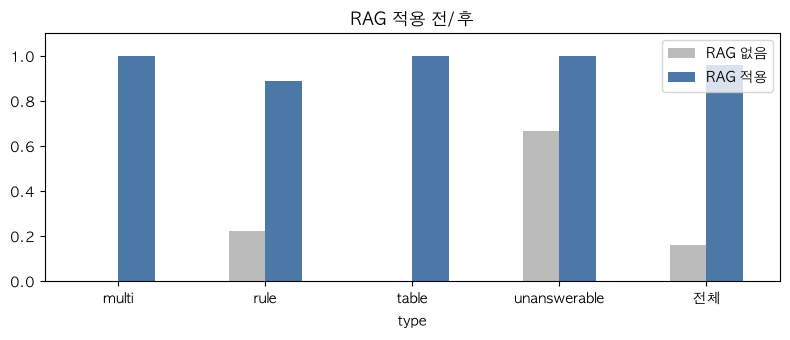

In [34]:
# RAG 전/후 정확도 비교 (같은 생성 모델, 같은 25문항)
def run_norag(q):
    r = chat(BEST_GEN, [{"role": "system", "content": SYS_NO_RAG}, {"role": "user", "content": q["question"]}])
    return dict(id=q["id"], type=q["type"], ok=judge(q, r["answer"]))
no_rag = pmap(run_norag, QA, desc="RAG 없음")
no_rag = pd.DataFrame(no_rag)
with_rag = gen_raw[gen_raw.model == BEST_GEN][["id", "type", "ok"]]
cmp_df = pd.DataFrame({"RAG 없음": no_rag.groupby("type").ok.mean(), "RAG 적용": with_rag.groupby("type").ok.mean()})
cmp_df.loc["전체"] = [no_rag.ok.mean(), with_rag.ok.mean()]
RESULTS["rag_vs_norag"] = cmp_df
display(cmp_df.style.format(precision=2).set_caption(f"{BEST_GEN} — 유형별 정확도"))
cmp_df.plot.bar(figsize=(8, 3.5), rot=0, color=["#bbbbbb", "#4c78a8"]); plt.ylim(0, 1.1); plt.title("RAG 적용 전/후"); plt.tight_layout(); plt.show()

> `unanswerable`(없는 정보) 문항은 RAG 없이도 "모르겠다" 고 답하면 정답입니다. 반면 `table`/`rule` 문항은 **RAG 가 없으면 사실상 맞힐 수 없습니다.** 모델이 책자를 본 적이 없기 때문입니다.

### 8.4 (선택) 대화 루프

```python
while True:
    q = input("질문 (종료: q) > ")
    if q.strip().lower() in ("q", "quit", "exit"): break
    rag.ask(q)
```

## 9. 실습 과제와 마무리

### 과제
1. **평가셋 확장** — `data/qa_eval.json` 에 질문 5개를 추가하세요 (다른 학과, 다른 유형). 가장 많이 틀리는 질문 유형은?
2. **조합 탐색** — 임베딩 × 청킹 조합 (예: `qwen3-embedding` × `structure`) 을 직접 돌려서 최고 조합을 찾으세요. 단계별 우승 조합이 전체 최적 조합과 같은가요?
3. **필터 자동화** — `detect_dept` 는 정규식 수준입니다. 학년·학기까지 질문에서 뽑아 필터에 추가해 보세요. (메타데이터 `grade` 필드 추가 필요)
4. **프레임워크 비교** — 같은 파이프라인을 LangChain 또는 LlamaIndex 로 구현하고 코드 길이·성능·디버깅 편의성을 비교하세요.
5. **도전** — 리랭커 모델 도입(`RUN_RERANK=True` 또는 cross-encoder), 표를 마크다운으로 변환해서 청킹, Streamlit UI 붙이기.

### 한계와 다음 단계
- 평가셋 25문항은 **방향을 보는 용도**입니다. 점수 차이가 작으면 우연일 수 있습니다. 실무에서는 수백 문항 + LLM-as-judge 를 씁니다.
- 키워드 채점은 단순합니다. 표현이 다르지만 맞는 답은 오답 처리될 수 있습니다.
- 다음 주제: RAG 평가 자동화(RAGAS 등), 멀티모달(표를 이미지로 처리), 에이전트형 RAG.

### FAQ / 트러블슈팅
| 증상 | 해결 |
|---|---|
| `ConnectionError` / Ollama 연결 실패 | Ollama 앱이 실행 중인지 확인 (`ollama serve`) |
| `model not found` (Ollama) | 1.2 셀이 알려 준 `ollama pull ...` 실행 |
| `OPENAI_API_KEY 가 없습니다` | 프로젝트 폴더에 `.env` 생성 → `OPENAI_API_KEY=sk-...` 저장 → 커널 재시작 |
| OpenAI `model_not_found` / 접근 불가 | 계정에서 쓸 수 있는 모델명으로 `GEN_MODELS`, `FAST_MODEL` 수정 |
| OpenAI `429 RateLimit` | `MAX_WORKERS` 를 줄이세요 (예: 3) |
| 임베딩이 너무 느림 | 모델 수를 줄이거나(`EMBED_MODELS` 일부 주석), `.cache/emb` 캐시 활용 |
| 메모리 부족으로 생성이 느림/실패 | `GEN_MODELS` 에서 큰 모델 제거 |
| 한글이 □ 로 깨져 보임 (그래프) | 1.2 셀의 `font.family` 에 설치된 한글 폰트 추가 |
| 결과가 실행할 때마다 조금 다름 | LLM 호출은 `temperature=0` 이지만 완전 결정적이진 않음. 임베딩/검색은 캐시되어 동일 |
| 캐시를 지우고 처음부터 | `.cache/` 폴더 삭제 |